<a href="https://colab.research.google.com/github/maratsanat/-Informatics_1sem-/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22hw_1_game_of_thrones_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

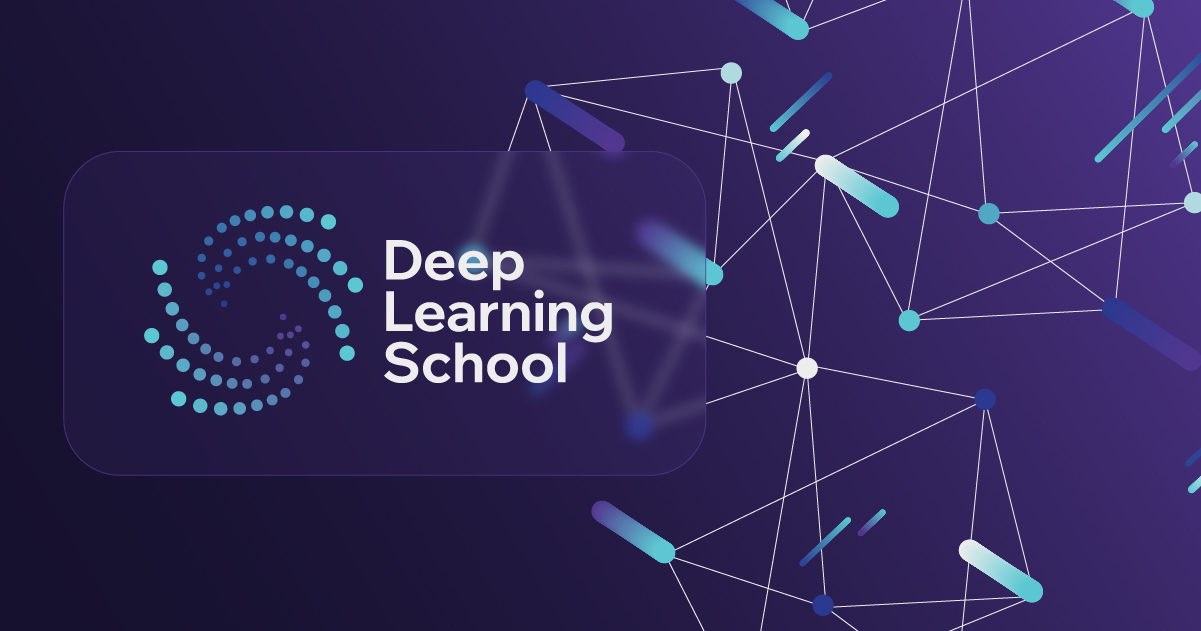

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Библиотека sklearn и классификация с помощью KNN</b></h1>

## Описание домашнего задания

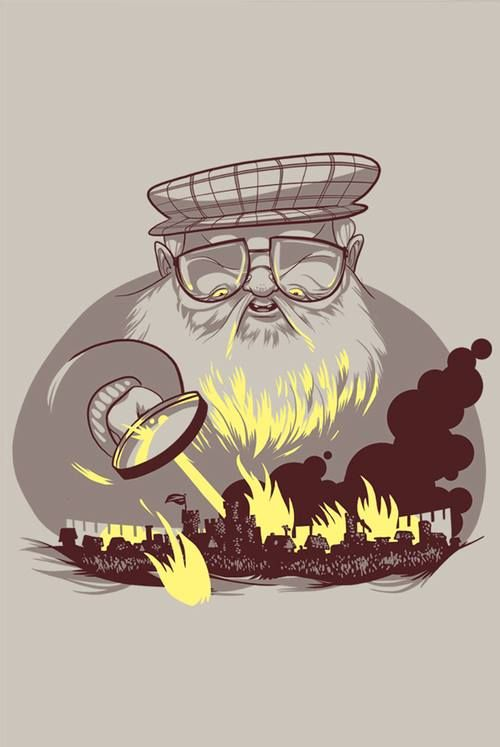

В данном задании вы будете работать с датасетом о персонажах из вселенной Игры Престолов [A Wiki of Ice and Fire](http://awoiaf.westeros.org/). Вам предстоит предсказать, кто из персонажей умрет, а кто останется вживых.



Описание данных:

* **name**: Имя персонажа

* **Title**: Социальный статус или знатность

* **House**: Дом, к которому принадлежит персонаж

* **Culture**: Социальная группа, к которой принадлежит персонаж

* **book1/2/3/4/5**: Появление персонажа в книге

* **Is noble**: Знатность персонажа, основанное на титуле

* **Age**: Отсчет времени: 305 AC

* **male**: Мужчина или женщина

* **dateOfBirth**: дата рождения

* **Spouse**: Имя супруги\а персонажа

* **Father**: Имя отца персонажа

* **Mother**: Имя матери персонажа

* **Heir**: Имя наследника персонажа

* **Is married**: Represents whether the character is married

* **Is spouse alive**: Represents whether character's spouse is alive

* **Is mother alive:** Жива ли мать персонажа

* **Is heir alive:** Жив ли наследник персонажа

* **Is father alive:** Указывает, жив ли отец персонажа

* **Number dead relations:** Количество умерших персонажей, с которыми персонаж связан

* **Popularity score:** Количество внутренних входящих и исходящих ссылок на страницу персонажей в вики http://awoiaf.westeros.org

Целевая переменная:
* **isAlive**: жив ли персонаж в книге

Оценивание:

Баллы считаются следующим образом:

1) $1.00 \geqslant score \geqslant 0.65$ --- 5 баллов

2) $0.65 > score \geqslant 0.50$ --- 4 балла

3) $0.50 > score \geqslant 0.45$ --- 3 балла

4) $0.45 > score \geqslant 0.40$ --- 2 балла

5) $0.40 > score \geqslant 0.35$ --- 1 балл

6) $0.35 > score$ --- 0 баллов

## Часть 1. Анализ и предобработка данных

Здесь вам необходимо сделать все шаги, которые обсуждались в первой части семинара.
* Предобработка данных
  * Обработка пропущенных данных
  * Создание новых признаков
  * Удаление ненужных столбцов
* Анализ данных
  * Анализ целевой переменной
  * Анализ признаков
  * Анализ влияния признаков на целевую переменную
* Подготовка данных для обучения модели

Загружаем датасет

In [67]:
!gdown 1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3 # test dataset
!gdown 1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v # train dataset

Downloading...
From: https://drive.google.com/uc?id=1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3
To: /content/game_of_thrones_test.csv
100% 37.3k/37.3k [00:00<00:00, 65.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v
To: /content/game_of_thrones_train.csv
100% 138k/138k [00:00<00:00, 62.1MB/s]


**Задание 1.1.** Импортируйте библиотеки pandas, matplotlib, seaborn

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

**Задание 1.2.** Загрузите датасет в Pandas DataFrame при помощи функции `read_csv`. Вместо дефолтных наименований строк `0,1,...`, при помощи параметра `index_col`, сделайте значения колонки `S.No` наименованиями строк:

In [69]:
data =pd.read_csv('game_of_thrones_train.csv', index_col='S.No')

print(data.head())
print(data.index.name)

                      name                 title  male   culture  dateOfBirth  \
S.No                                                                            
1     Viserys II Targaryen                   NaN     1       NaN          NaN   
2              Walder Frey  Lord of the Crossing     1  Rivermen        208.0   
3             Addison Hill                   Ser     1       NaN          NaN   
4              Aemma Arryn                 Queen     0       NaN         82.0   
5           Sylva Santagar            Greenstone     0   Dornish        276.0   

                  mother            father                heir  \
S.No                                                             
1     Rhaenyra Targaryen  Daemon Targaryen  Aegon IV Targaryen   
2                    NaN               NaN                 NaN   
3                    NaN               NaN                 NaN   
4                    NaN               NaN                 NaN   
5                    NaN            

Посмотрите, какие типы данных представлены в нашем датасете

Знакомый нам метод describe() возвращает различную информацию для столбцов с числовыми типами данных, и с типами данных *object*

Давайте посмотрим на вывод для типа данных *object*. Для этого:
- сначала применим метод describe(). Укажем в качестве аргумента тип данных столбцов, статистику по которым мы хотим посмотреть (см. https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)
- для удобства восприятия транспонируем таблицу

In [70]:
data.describe(include = 'object').T

,count,unique,top,freq
name,1557,1557,Melara Hetherspoon,1
title,717,195,Ser,306
culture,488,51,Northmen,94
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6


Теперь давайте посмотрим на столбцы с числовыми типами данных. Дополните код ниже. Для удобства восприятия мы транспонировали таблицу и ограничили вывод тремя столбцами - количество строк без NaN, максимальное и минимальное значение (о кастомизации вариантах вывода describe() вы можете почитать в документации по ссылке выше).


In [71]:
numeric_stats = data.describe(include=['number']).loc[['count', 'max', 'min']].T
print("\nСтатистика для числовых колонок (count, max, min):")
print(numeric_stats)


Статистика для числовых колонок (count, max, min):
                   count    max   min
male              1557.0    1.0   0.0
dateOfBirth        279.0  299.0 -25.0
book1             1557.0    1.0   0.0
book2             1557.0    1.0   0.0
book3             1557.0    1.0   0.0
book4             1557.0    1.0   0.0
book5             1557.0    1.0   0.0
isAliveMother       18.0    1.0   0.0
isAliveFather       22.0    1.0   0.0
isAliveHeir         21.0    1.0   0.0
isAliveSpouse      200.0    1.0   0.0
isMarried         1557.0    1.0   0.0
isNoble           1557.0    1.0   0.0
age                279.0  100.0   0.0
numDeadRelations  1557.0   15.0   0.0
popularity        1557.0    1.0   0.0
isAlive           1557.0    1.0   0.0


Так мы проверим, есть ли в данных неадекватнные значения.   Большинство числовых столбцов - это числа от 0 до 1. Отрицательные значения `dateOfBirth` не являются ошибкой. Значения age и `numDeadRelations` также выглядят адекватными. Можно переходить к дальнейшим шагам анализа (анонс - а в тестовых данных нас будет ждать сюрприз).

**Задание 1.3.** Предобработка (очистка) данных.

В нашем домашнем задании все пропуски в данных (missing values) уже закодированы как NaN. Проанализируйте, в каких колонках и как часто встречаются NaN значения. Далее вам надо будет принять решение, как их обрабатывать.

In [72]:


print("Размер исходного датасета:", data.shape)
print("Количество NaN до обработки:", data.isnull().sum().sum())

# Создаем копию для очищенного датасета
data_clean = data.copy()

# 1. Анализ пропусков (для понимания масштаба)
missing_count = data_clean.isnull().sum()
missing_percent = (missing_count / len(data_clean)) * 100

print("\n=== КОЛОНКИ С ПРОПУСКАМИ (до обработки) ===")
missing_df = pd.DataFrame({
    'Количество NaN': missing_count[missing_count > 0],
    'Процент': missing_percent[missing_count > 0].round(2)
})
print(missing_df.sort_values('Процент', ascending=False))

# 2. ЗАПОЛНЕНИЕ ПРОПУСКОВ (БЕЗ УДАЛЕНИЯ СТРОК)

# Для числовых колонок - заполняем медианой (устойчива к выбросам)
numeric_cols = data_clean.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if data_clean[col].isnull().any():
        median_val = data_clean[col].median()
        data_clean[col].fillna(median_val, inplace=True)
        print(f"Числовая колонка '{col}': заполнено {data_clean[col].isnull().sum()} пропусков медианой {median_val:.2f}")

# Для категориальных колонок - заполняем модой (самым частым значением)
categorical_cols = data_clean.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if data_clean[col].isnull().any():
        mode_val = data_clean[col].mode()[0]  # берем первое модальное значение
        data_clean[col].fillna(mode_val, inplace=True)
        print(f"Категориальная колонка '{col}': заполнено пропусков значением '{mode_val}'")

# 3. Проверка результата
print("\n=== РЕЗУЛЬТАТ ОБРАБОТКИ ===")
print(f"Размер датасета после обработки: {data_clean.shape} (строки сохранены!)")
print(f"Количество NaN после обработки: {data_clean.isnull().sum().sum()}")

if data_clean.isnull().sum().sum() == 0:
    print("✓ Все пропуски успешно заполнены!")
else:
    print("⚠ Остались пропуски в колонках:")
    print(data_clean.isnull().sum()[data_clean.isnull().sum() > 0])

# 4. Сохраняем очищенный датасет (опционально)
# df_clean.to_csv('train_cleaned.csv')

Размер исходного датасета: (1557, 25)
Количество NaN до обработки: 16780

=== КОЛОНКИ С ПРОПУСКАМИ (до обработки) ===
               Количество NaN  Процент
mother                   1539    98.84
isAliveMother            1539    98.84
heir                     1536    98.65
isAliveHeir              1536    98.65
father                   1535    98.59
isAliveFather            1535    98.59
isAliveSpouse            1357    87.15
spouse                   1357    87.15
dateOfBirth              1278    82.08
age                      1278    82.08
culture                  1069    68.66
title                     840    53.95
house                     381    24.47
Числовая колонка 'dateOfBirth': заполнено 0 пропусков медианой 272.00
Числовая колонка 'isAliveMother': заполнено 0 пропусков медианой 1.00
Числовая колонка 'isAliveFather': заполнено 0 пропусков медианой 0.00
Числовая колонка 'isAliveHeir': заполнено 0 пропусков медианой 1.00
Числовая колонка 'isAliveSpouse': заполнено 0 пропусков ме

В этом задании удалять строки с NaN (dropna) мы не будем по следующим причинам:
- в обучающем датасете много признаков с большим количество пропусков. Если удалять все строки с NaN, то размер выборки сильно уменьшится. Мы потеряем много данных, которые можно было бы использовать для построения более точной модели.
- тестовом датасете также много признаков с NaN (вы можете в этом убедиться, если скачаете датасет и совершите с ним те же действия, что выше проделали с обучаюшим датасетом). Поэтому нам все-равно придется придумать способ кодировать NaN, чтобы модель делала прогнозы для всех персонажей из тестового датасета. Для этого нам потребуется сохранять, а не удалять данные в обучающем датасете.     



Как вы могли заметить, в наших данных очень много пропущенных значений, причём в некоторых случая пропущена **большая** часть значений. Поэтому заполнять по умолчанию медианой/средним/модой в данном случае - не самый лучший способ (однако, это довольно часто используемый метод заполнения, который может пригодиться вам в будущем)

Ниже мы посмотрим, как можно работать с признаками с большим количеством пропущенных значений.

**Задание 1.4.** Числовые признаки

У нас есть **признак popularity**. Постройте гистограмму распределения данного признака с количеством интервалов (bins), равным 50 (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html)

=== Статистика признака popularity ===
count    1557.000000
mean        0.062400
std         0.121416
min         0.000000
25%         0.013378
50%         0.023411
75%         0.063545
max         1.000000
Name: popularity, dtype: float64
Пропуски: 0
Тип данных: float64


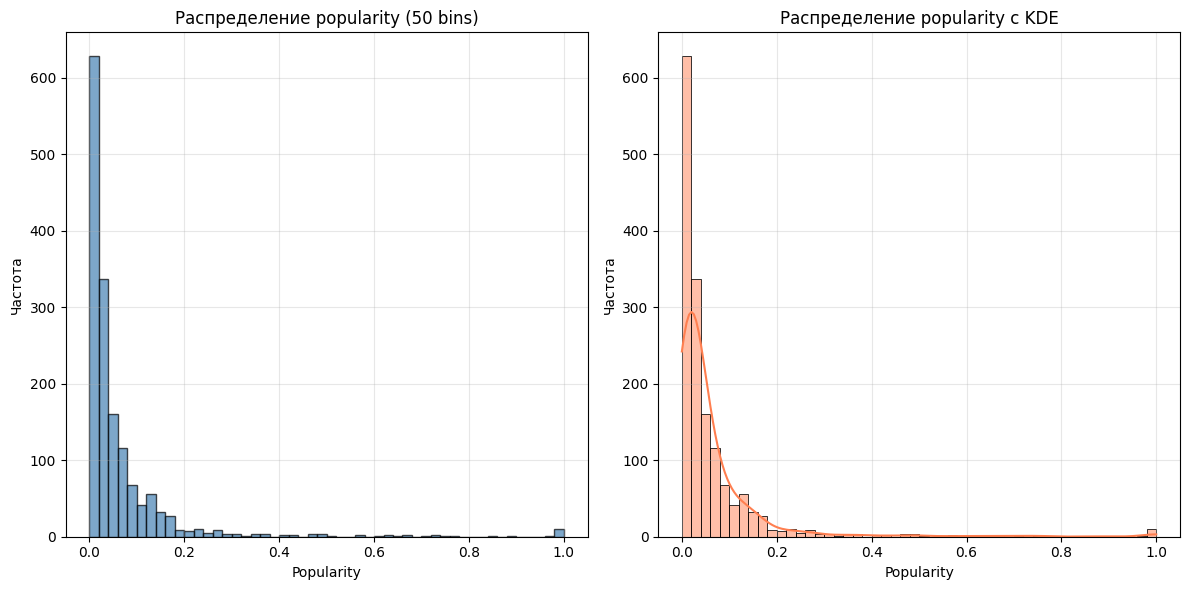

In [73]:
if 'popularity' in data_clean.columns:
    print("=== Статистика признака popularity ===")
    print(data_clean['popularity'].describe())
    print(f"Пропуски: {data_clean['popularity'].isnull().sum()}")
    print(f"Тип данных: {data_clean['popularity'].dtype}")
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.hist(data_clean['popularity'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    plt.title('Распределение popularity (50 bins)')
    plt.xlabel('Popularity')
    plt.ylabel('Частота')
    plt.grid(True, alpha=0.3)
    plt.subplot(1, 2, 2)
    sns.histplot(data_clean['popularity'], bins=50, kde=True, color='coral')
    plt.title('Распределение popularity с KDE')
    plt.xlabel('Popularity')
    plt.ylabel('Частота')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

else:
    print("Признак 'popularity' не найден в датасете. Доступные колонки:")
    print(data_clean.columns.tolist())

Распределение сильно несимметрично. Можно преобразовать данный признак, например, по формуле `np.log10(data["popularity"]*M+1)` (добавляем 1 ради логарифма, так как для некоторых персонажей `popularity==0`). В качестве M можно попробовать, например, M=100 или другое число.

При желании для `popularity` вы можете использовать свой способ шкалирования признаков с несимметричным распределением.



=== ИТОГОВЫЙ ПРИЗНАК (M=100) ===
count    1557.000000
mean        0.621287
std         0.402654
min         0.000000
25%         0.368806
50%         0.523894
75%         0.866554
max         2.004321
Name: popularity_log, dtype: float64


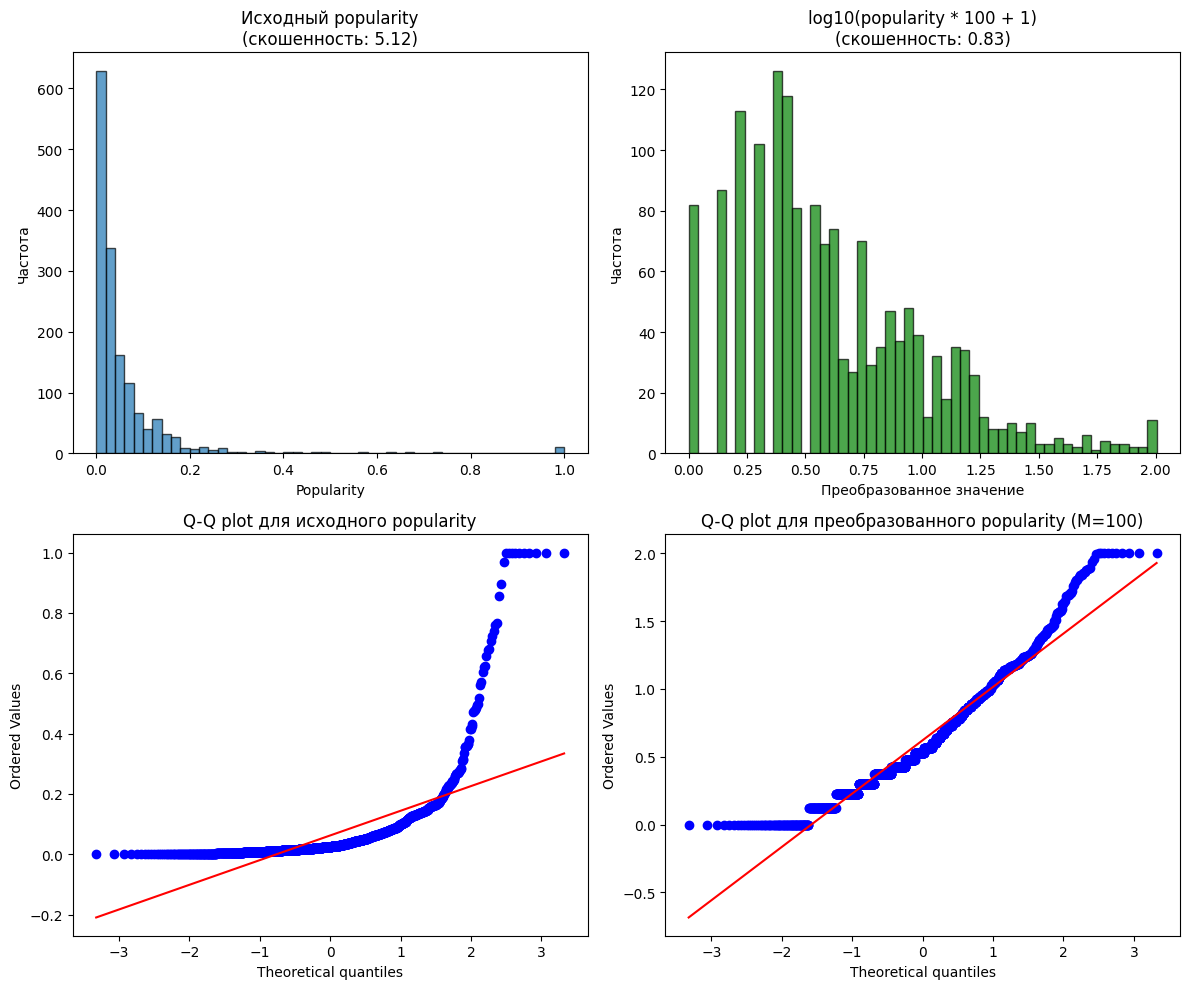

In [74]:
optimal_M = 100

data_clean['popularity_log'] = np.log10(data_clean['popularity'] * optimal_M + 1)

print(f"\n=== ИТОГОВЫЙ ПРИЗНАК (M={optimal_M}) ===")
print(data_clean['popularity_log'].describe())

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Исходный
axes[0, 0].hist(data_clean['popularity'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].set_title(f'Исходный popularity\n(скошенность: {data_clean["popularity"].skew():.2f})')
axes[0, 0].set_xlabel('Popularity')
axes[0, 0].set_ylabel('Частота')

# Преобразованный
axes[0, 1].hist(data_clean['popularity_log'], bins=50, edgecolor='black', alpha=0.7, color='green')
axes[0, 1].set_title(f'log10(popularity * {optimal_M} + 1)\n(скошенность: {data_clean["popularity_log"].skew():.2f})')
axes[0, 1].set_xlabel('Преобразованное значение')
axes[0, 1].set_ylabel('Частота')

from scipy import stats

stats.probplot(data_clean['popularity'].dropna(), dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q plot для исходного popularity')

stats.probplot(data_clean['popularity_log'].dropna(), dist="norm", plot=axes[1, 1])
axes[1, 1].set_title(f'Q-Q plot для преобразованного popularity (M={optimal_M})')

plt.tight_layout()
plt.show()

В качестве альтернативного подхода вы можете попробовать дискретизацию признака popularity на основе квантилей (quantile binning), используя функцию qcut() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html). В этом случае вы преобразуете числовой признак popularity в категориальный, для которого в дальнейшем надо будет применить one-hot кодирование.

Теперь давайте обработаем **признак numDeadRelations**.
Посмотрите на частотное распределение этого признака. Лишь для малого числа персонажей `numDeadRelations>0`.

Создайте признак `boolDeadRelations`. Давайте упростим признак `numDeadRelations`, и просто поделим людей на тех, у кого были хоть какие то отношения с мертвыми персонажами, т.е. `numDeadRelations > 0`, и те, у которых не было, т.е. `numDeadRelations = 0`.

count    1557.000000
mean        0.187540
std         1.114648
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        15.000000
Name: numDeadRelations, dtype: float64

Частотное распределение (первые 20 значений):
numDeadRelations
0     1488
1       24
2        4
3        4
4        7
5       10
6        3
7        7
8        2
9        1
10       4
11       1
12       1
15       1
Name: count, dtype: int64

Доля записей с numDeadRelations = 0: 95.57%
Доля записей с numDeadRelations > 0: 4.43%


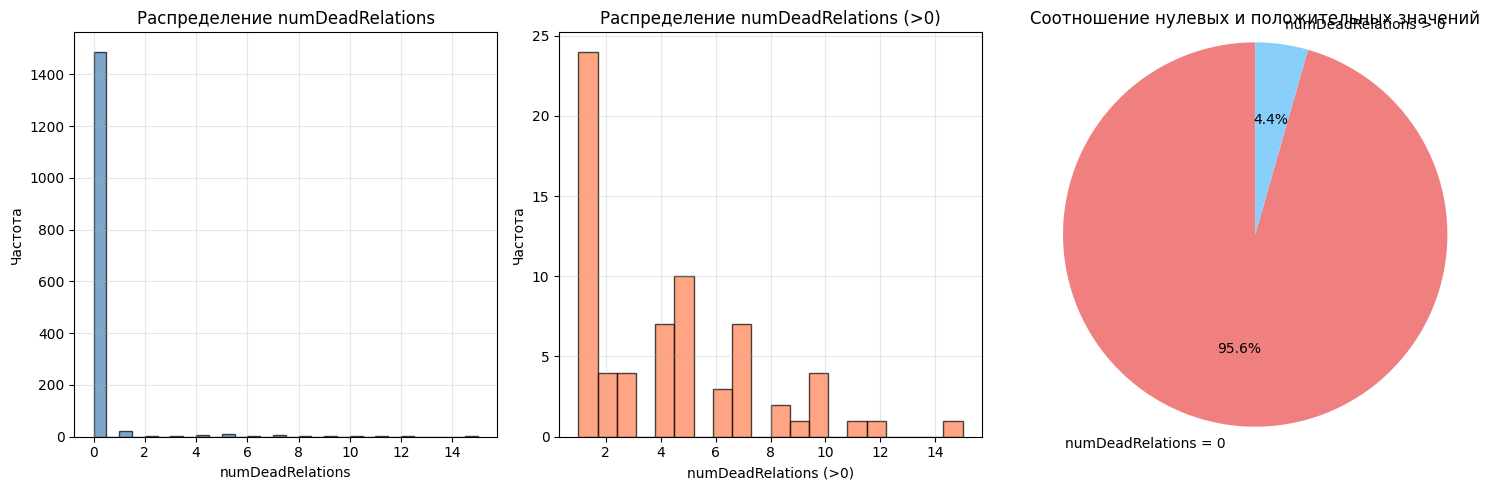


=== СОЗДАН НОВЫЙ ПРИЗНАК: boolDeadRelations ===
Тип данных: int64
Уникальные значения: [1 0]

Распределение boolDeadRelations:
0 (нет отношений с мертвыми): 1488 записей (95.57%)
1 (есть отношения с мертвыми): 69 записей (4.43%)


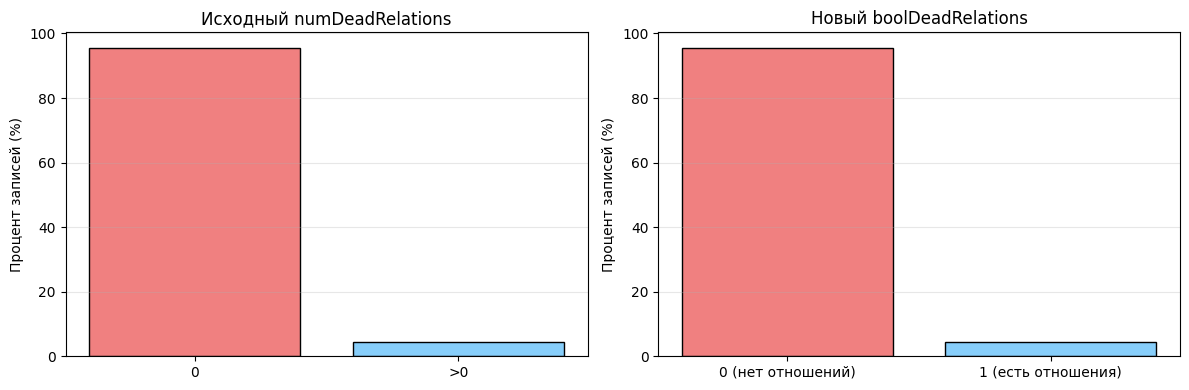

Доступные признаки: ['name', 'title', 'male', 'culture', 'dateOfBirth', 'mother', 'father', 'heir', 'house', 'spouse', 'book1', 'book2', 'book3', 'book4', 'book5', 'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse', 'isMarried', 'isNoble', 'age', 'numDeadRelations', 'popularity', 'isAlive', 'popularity_log', 'boolDeadRelations']

Первые несколько строк с новым признаком:
      numDeadRelations  boolDeadRelations
S.No                                     
1                   11                  1
2                    1                  1
3                    0                  0
4                    0                  0
5                    0                  0
6                    5                  1
7                    0                  0
8                    5                  1
9                    0                  0
10                   0                  0


In [75]:

print(data_clean['numDeadRelations'].describe())

value_counts = data_clean['numDeadRelations'].value_counts().sort_index()
print(f"\nЧастотное распределение (первые 20 значений):")
print(value_counts.head(20))

zero_percent = (data_clean['numDeadRelations'] == 0).mean() * 100
print(f"\nДоля записей с numDeadRelations = 0: {zero_percent:.2f}%")

positive_percent = (data_clean['numDeadRelations'] > 0).mean() * 100
print(f"Доля записей с numDeadRelations > 0: {positive_percent:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(data_clean['numDeadRelations'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_title('Распределение numDeadRelations')
axes[0].set_xlabel('numDeadRelations')
axes[0].set_ylabel('Частота')
axes[0].grid(True, alpha=0.3)

positive_values = data_clean['numDeadRelations'][data_clean['numDeadRelations'] > 0]
if len(positive_values) > 0:
    axes[1].hist(positive_values, bins=20, edgecolor='black', alpha=0.7, color='coral')
    axes[1].set_title('Распределение numDeadRelations (>0)')
    axes[1].set_xlabel('numDeadRelations (>0)')
    axes[1].set_ylabel('Частота')
    axes[1].grid(True, alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'Нет положительных значений', ha='center', va='center')
    axes[1].set_title('Распределение numDeadRelations (>0)')

sizes = [zero_percent, positive_percent]
labels = ['numDeadRelations = 0', 'numDeadRelations > 0']
colors = ['lightcoral', 'lightskyblue']
axes[2].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
axes[2].set_title('Соотношение нулевых и положительных значений')
axes[2].axis('equal')

plt.tight_layout()
plt.show()

data_clean['boolDeadRelations'] = (data_clean['numDeadRelations'] > 0).astype(int)

print("\n=== СОЗДАН НОВЫЙ ПРИЗНАК: boolDeadRelations ===")
print(f"Тип данных: {data_clean['boolDeadRelations'].dtype}")
print(f"Уникальные значения: {data_clean['boolDeadRelations'].unique()}")

bool_counts = data_clean['boolDeadRelations'].value_counts()
print(f"\nРаспределение boolDeadRelations:")
print(f"0 (нет отношений с мертвыми): {bool_counts.get(0, 0)} записей ({bool_counts.get(0, 0)/len(data_clean)*100:.2f}%)")
print(f"1 (есть отношения с мертвыми): {bool_counts.get(1, 0)} записей ({bool_counts.get(1, 0)/len(data_clean)*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['0', '>0'], [zero_percent, positive_percent], color=['lightcoral', 'lightskyblue'], edgecolor='black')
axes[0].set_title('Исходный numDeadRelations')
axes[0].set_ylabel('Процент записей (%)')
axes[0].grid(True, alpha=0.3, axis='y')

new_zero_percent = (data_clean['boolDeadRelations'] == 0).mean() * 100
new_one_percent = (data_clean['boolDeadRelations'] == 1).mean() * 100
axes[1].bar(['0 (нет отношений)', '1 (есть отношения)'], [new_zero_percent, new_one_percent],
            color=['lightcoral', 'lightskyblue'], edgecolor='black')
axes[1].set_title('Новый boolDeadRelations')
axes[1].set_ylabel('Процент записей (%)')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


print(f"Доступные признаки: {data_clean.columns.tolist()}")
print(f"\nПервые несколько строк с новым признаком:")
print(data_clean[['numDeadRelations', 'boolDeadRelations']].head(10))

Наконец, давайте посмотрим на **признак age**. В нем очень много пропущенных значений. Для того, чтобы использовать в модели информацию о возрасте персонажа, мы создадим два новых признака: `age_value` и `age_no_data`

- Там где возраст указан, age_value принимает значение `age`, а `age_no_data` - значение 0.
- Там где возраст не указан, `age_value` принимает значение 0, а `age_no_data` - значение 1.  

Фактически, в переменной `age` мы заменяем NaN на 0, но одновременно добавляем в модель еще один бинарный признак `age_no_data`, несущий информацию о том, у каких персонажей не был указан возраст:        

In [76]:
data['age_value'] = data['age'].fillna(0)
data['age_no_data'] = [1 if np.isnan(x) else 0 for x in data['age']]

Этот способ чем-то похож на работу с категориальной переменными с пропущенными значениями, когда мы добавляем еще одну категорию no_data и заменяем NaN на значение этой категории.

Если вы заходите похожим образом образом обработать признак `dateOfBirth`, **обратите внимание**, что у одних и тех же персонажей не указан и возраст, и год рождения.
То есть созданные признаки `age_no_data` и `dateOfBirth_no_data` будут полностью совпадать, и в модель надо будет включать только один из признаков: или `age_no_data`, или `dateOfBirth_no_data`.

**Задание 1.5.** Категориальные признаки с большим количеством категорий

**Признак culture** содержит информацию о принадлежности к одному из народов во вселенной Игры Престолов.

Давайте посмотрим, какие значения принимает данный признак. По умолчанию метод `value_counts()` игнорирует пропуски в данных, поэтому используем этот метод с параметром **dropna** со значением **False** (см. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.value_counts.html)

In [77]:
data['culture'].value_counts(dropna=False)

,count
culture,
NaN,1069
Northmen,94
Ironborn,91
Free Folk,45
Braavosi,39
Valyrian,28
Ghiscari,17
Dornish,17
Dothraki,17


Из полученного частотного распределения видно, что для большого числа персонажей значения данного признака не указаны. Также есть много редких значений признака, которые в выборке повторяются один или несколько раз. Причина отчасти в том, что один и тот же народ упоминается в нашем датасете под разными названиями.

Данную проблему мы попытаемся решить, сгруппировав народы в более крупные категории. Так мы одновременно решим проблему того, что один и тот же народ назван в выборке разными способами.

Предоженный вариант группировки имеет определенную логику. Выделяются следующие группы:
- старые нации, которые уже не сущевали как отдельные народы на момент повествования основной линии повествования романов, но отдельные потомки могли еще быть живы
- народы, проживающие в королевствах континента Весторос (для каждого королевства - своя группа)
- народы континента Эссос
- прочие народы

In [78]:
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

**Обратите внимание, что некоторые варианты названий народов встречаются только в тестовых данных, и не встречаются в обучающих данных.** Такая ситуация нередко случается на практике. Поэтому, после обработки обучающих данных и обучения модели важно задать для модели правило, как она должна обрабатывать "незнакомые" категории в категориальных признаках. Например, можно относить объекты с "незнакомой" категорией к некоторой существующей категории или указать формулу расчета для "незнакомой" категории.     

Предложенный вам словарь `cultures_grouped` составлен по всем значениям признака `culture`, встречающимся в тренировочном либо в тестовом датасете. Здесь важно, что все укрупненные категории (ключи/keys словаря `cultures_grouped`) представлены в обоих датасетах, а уникальные для тестового датасета названия народов - это отдельные названия народов внутри укрупненных категорий (значения/values словаря). Поэтому, когда вы будете работать с тестовыми - просто применяйте этот словарь без указания правила обработки "незнакомых" категорий.

Давайте приступим к кодировке значений признака culture.
Для этого сначала инвертируем словарь *cultures_grouped*

In [79]:
#Довольно просто инвертировать словарь, где ключу соответствует одно значение
#В нашем случае ключу соответствует список значений.
#Ниже показан пример, как можно инвертировать такой словарь

d = {'A': ['a1', 'a2', 'a3'],
     'B': ['b1', 'b2', 'b3', 'b4']}

d_inverted = {}
for k in d.keys():
  for v in d[k]:
      d_inverted.update({v:k})

d_inverted

{'a1': 'A', 'a2': 'A', 'a3': 'A', 'b1': 'B', 'b2': 'B', 'b3': 'B', 'b4': 'B'}

In [80]:
# Исходный словарь с группировкой культур
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],  # Заметим дубликат 'ironborn'
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans', 'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen', 'meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']
}

# Инвертируем словарь: каждому названию народа сопоставляем укрупненную категорию
cultures_grouped_inverted = {}

for category, culture_list in cultures_grouped.items():
    for culture in culture_list:
        cultures_grouped_inverted[culture] = category

# Проверим результат
print("Инвертированный словарь (первые 10 элементов):")
count = 0
for culture, category in cultures_grouped_inverted.items():
    print(f"'{culture}' -> '{category}'")
    count += 1
    if count >= 10:
        print("...")
        break

print(f"\nВсего элементов в инвертированном словаре: {len(cultures_grouped_inverted)}")

# Проверим, что дубликаты обработаны корректно
# Например, 'ironborn' встречается дважды в исходном словаре, но в инвертированном будет одно значение
print(f"\nironborn относится к категории: '{cultures_grouped_inverted.get('ironborn')}'")

Инвертированный словарь (первые 10 элементов):
'valyrian' -> 'Old Nations'
'first men' -> 'Old Nations'
'andal' -> 'Old Nations'
'andals' -> 'Old Nations'
'rhoynar' -> 'Old Nations'
'northmen' -> 'the North'
'northern mountain clans' -> 'the North'
'crannogmen' -> 'the North'
'ironborn' -> 'the Iron Islands'
'ironmen' -> 'the Iron Islands'
...

Всего элементов в инвертированном словаре: 59

ironborn относится к категории: 'the Iron Islands'


Теперь создадим новый столбец с укрупненными значениями culture.

Для этого будем использовать метод `map()` с инвертированным словарем в качестве аргумента (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html)

Обратите внимание, что в словаре названия народов указаны в нижнем регистре. А в датасете используется как нижний, так и верхний регистр. Поэтому перед применением метода `map()` переведем значения столбца culture в нижний регистр при помощи метода `str.lower()` (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.lower.html).

In [81]:
data['culture_grouped'] = data['culture'].str.lower().map(cultures_grouped_inverted)

Осталось заменить все NaN в созданном столбце на категорию `culture_no_data`:

In [82]:
data['culture_grouped'] = data['culture_grouped'].fillna('culture_no_data')

Распределение сгруппированной переменной выглядит гораздо лучше. Но по прежнему есть несколько слабо представленых групп.

Дальнейшую работу с этим признаком проводите на свое усмотрение для повышения качества прогноза модели. Например, можно объединить несколько слабо представленных категорий в одну или применить другой подход.

**Задание 1.6.** Категориальные признаки в линейных моделях

Для включения категориальных признаков в линейную модель их нужно преобразовать в числовые признаки.

Если признак принимает одно из двух возможных значений (например, персонаж "появляется" или "не появляется" в 1-й книге), он напрямую кодируется в бинарный признак ("появляется" -> 1, "не появляется" -> 0). Если признак принимает больше двух значений, его можно преобразовать в несколько бинарных при помощи one-hot преобразования. В некоторых случаях бывает полезно объединить некоторые категории, как мы это поступили с признаком *culture*.

Порядковых признаков у нас в задаче нет, поэтому рассматривать их здесь мы не будем.

Для того, чтобы найти все порядковые признаки, посмотрим на количество уникальных значений, которые встречаются в столбцах. Для столбцов с типом object количество уникальных значений мы выводили  при помощи метода `describe()` в задании 1.2.

Чтобы посмотреть количество уникальных значений для всех столбцов, можно воспользоваться методом nunique() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html)

In [83]:
# Количество уникальнх значений в каждом столбце
data.nunique()

,0
name,1557
title,195
male,2
culture,51
dateOfBirth,105
mother,16
father,19
heir,20
house,315
spouse,186


In [84]:
# Для числовых столбцов можно вывести в одну таблицу более детальную статистику, объединив выводы describe() и nunique()
# Код ниже требуется дополнить по аналогии с заданием 1.2.
data.describe(include = ['number']).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique())

,count,min,max,N_unique_values
male,1557.0,0.0,1.0,2
dateOfBirth,279.0,-25.0,299.0,105
book1,1557.0,0.0,1.0,2
book2,1557.0,0.0,1.0,2
book3,1557.0,0.0,1.0,2
book4,1557.0,0.0,1.0,2
book5,1557.0,0.0,1.0,2
isAliveMother,18.0,0.0,1.0,2
isAliveFather,22.0,0.0,1.0,2
isAliveHeir,21.0,0.0,1.0,2


Посмотрев на количество уникальных значений мы можем выделить категориальные признаки. Например, `popularity` принимает значения от 0 до 1, но это непрерывный числовой признак. Остальные признаки со значениями от 0 до 1 - принимают только два значения, то есть являются бинарными.

Бинарные признаки без NaN полностью готовы для включения в модель. Некоторые бинарные признаки содержат пропуски, поэтому, если вы захотите включить их в модель, их потребуется обработать.

Для бинарных признаков их связь с зависимой переменной можно прикинуть по таблице корреляций. Для категориальных признаков с количеством значений больше двух (или с двумя значениями и NaN) можно сделать one-hot преобразования и посчитать корреряцию зависимой переменной с набором сгенерированных бинарных признаков.
В качестве альтернативного подхода можно использовать сравнение средних значений зависимой переменной для разных категорий исследуемого признака. Чем сильнее различаются средние значения целевой переменной между категориями, тем вероятнее, что данный признак связан с зависимой переменной.

In [85]:
# попробуйте провести сравнение средних зависимой пременной isAlive для признака isAliveSpouse
# одним из приведенных ниже способов:

# data.groupby('НАЗВАНИЕ ПРИЗНАКА', dropna = False)['isAlive'].mean()
# pd.pivot_table(data = data, values = 'isAlive', index = 'НАЗВАНИЕ ПРИЗНАКА', aggfunc=['mean', 'count'], dropna=False)
pivot_result = pd.pivot_table(
    data=data,
    values='isAlive',
    index='isAliveSpouse',
    aggfunc=['mean', 'count'],
    dropna=False
)
print(pivot_result)

                   mean   count
                isAlive isAlive
isAliveSpouse                  
0.0            0.619048      42
1.0            0.753165     158
NaN            0.786293    1357


**Задание 1.7.** Проанализируйте признаки.
  * Обработайте категориальные признаки и переведите их в числа. Можете выбрать любой кодировщик. Не забудьте, что потом аналогичным образом вам надо будет преобразовывать тестовый датасет, используя тот же алгоритм кодирования признаков.
  * Проанализируйте количественные признаки. Есть ли корреляция между признаками?

In [86]:

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer


print(data.info())

print(data.dtypes)

numeric_features = data.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()


target = 'isAlive'
if target in numeric_features:
    numeric_features.remove(target)
if target in categorical_features:
    categorical_features.remove(target)

<class 'pandas.core.frame.DataFrame'>
Index: 1557 entries, 1 to 1557
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              1557 non-null   object 
 1   title             717 non-null    object 
 2   male              1557 non-null   int64  
 3   culture           488 non-null    object 
 4   dateOfBirth       279 non-null    float64
 5   mother            18 non-null     object 
 6   father            22 non-null     object 
 7   heir              21 non-null     object 
 8   house             1176 non-null   object 
 9   spouse            200 non-null    object 
 10  book1             1557 non-null   int64  
 11  book2             1557 non-null   int64  
 12  book3             1557 non-null   int64  
 13  book4             1557 non-null   int64  
 14  book5             1557 non-null   int64  
 15  isAliveMother     18 non-null     float64
 16  isAliveFather     22 non-null     float64
 17  

                      male  dateOfBirth     book1     book2     book3  \
male              1.000000    -0.053117  0.050526  0.024079 -0.008100   
dateOfBirth      -0.053117     1.000000  0.097634  0.466285  0.503627   
book1             0.050526     0.097634  1.000000  0.278116  0.145458   
book2             0.024079     0.466285  0.278116  1.000000  0.380968   
book3            -0.008100     0.503627  0.145458  0.380968  1.000000   
book4            -0.101674     0.612802 -0.009461  0.102247  0.329153   
book5             0.023022     0.222051  0.180542  0.135720  0.226547   
isAliveMother          NaN          NaN       NaN       NaN       NaN   
isAliveFather          NaN          NaN -0.118345 -0.118345       NaN   
isAliveHeir            NaN          NaN       NaN       NaN       NaN   
isAliveSpouse     0.288754     0.235612  0.085139  0.040037  0.027963   
isMarried        -0.094385    -0.311075  0.018072  0.153332  0.165407   
isNoble           0.133807    -0.490445  0.041593 -

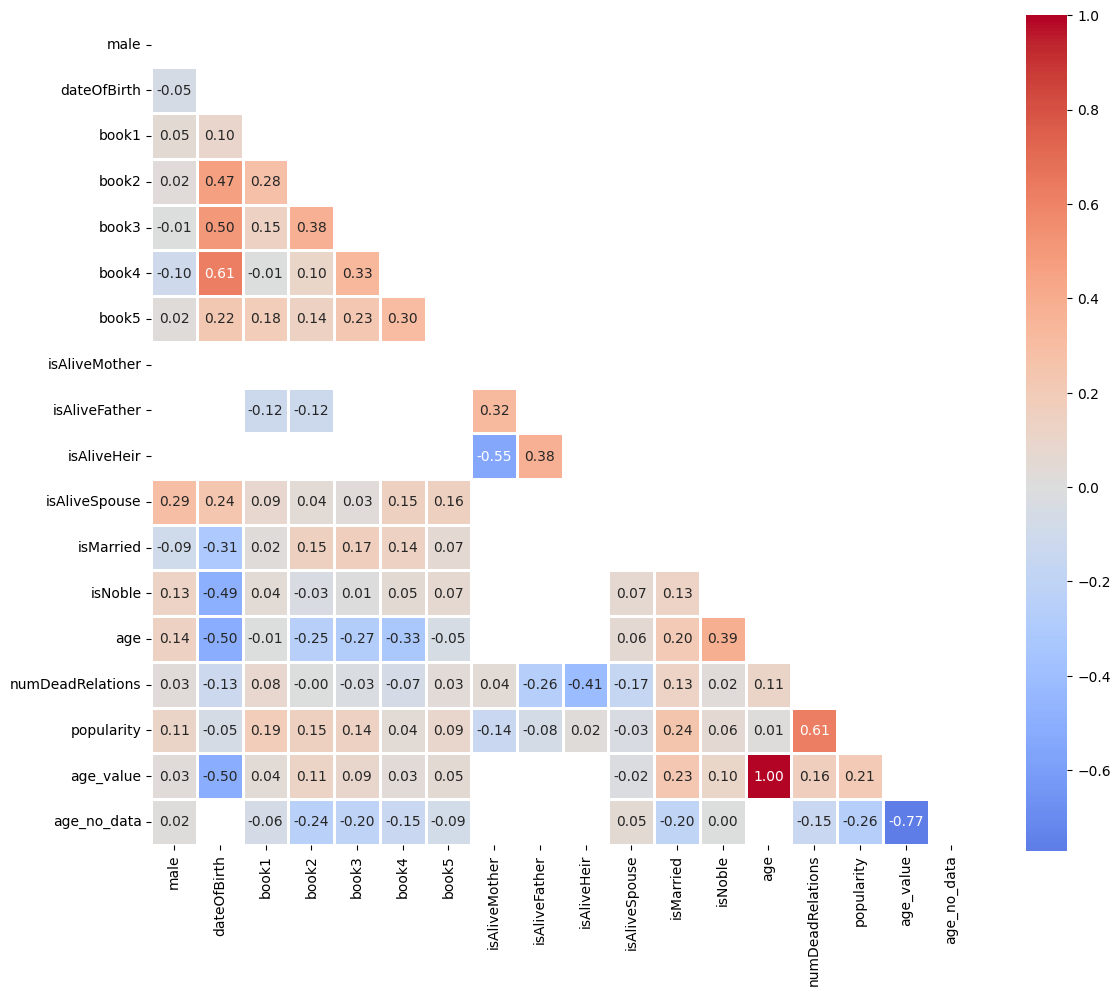

isAlive             1.000000e+00
dateOfBirth         6.558810e-01
isAliveHeir         3.952847e-01
book4               2.840140e-01
isAliveFather       1.549826e-01
isAliveSpouse       1.223408e-01
age_no_data         1.136289e-01
book5               3.253064e-02
book3               1.842685e-02
isAliveMother       3.510833e-17
isMarried          -4.938068e-02
book2              -5.599775e-02
isNoble            -6.057220e-02
book1              -1.124682e-01
male               -1.482904e-01
age_value          -1.819384e-01
popularity         -1.941868e-01
numDeadRelations   -1.988762e-01
age                -3.111149e-01
Name: isAlive, dtype: float64


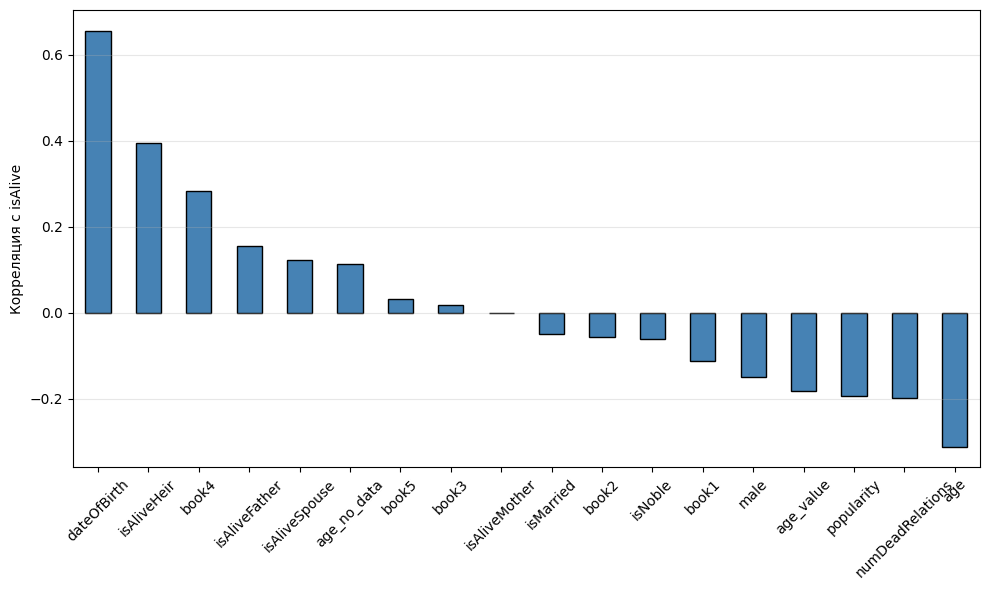

In [87]:

if len(numeric_features) > 0:
    corr_matrix = data[numeric_features].corr()

    print(corr_matrix)

    strong_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) > 0.5:
                strong_corr.append(f"{corr_matrix.columns[i]} - {corr_matrix.columns[j]}: {corr_matrix.iloc[i, j]:.3f}")

    if strong_corr:
        for corr in strong_corr:
            print(corr)
    else:
          print("Сильных корреляций не обнаружено")
    plt.figure(figsize=(12, 10))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, square=True, linewidths=1)
    plt.tight_layout()
    plt.show()

    if target in data.columns:
        corr_with_target = data[numeric_features + [target]].corr()[target].sort_values(ascending=False)
        print(corr_with_target)

        plt.figure(figsize=(10, 6))
        corr_with_target.drop(target).plot(kind='bar', color='steelblue', edgecolor='black')
        plt.ylabel('Корреляция с isAlive')
        plt.grid(True, alpha=0.3, axis='y')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
else:
    print("Нет числовых признаков для анализа корреляции")

In [88]:

data_encoded = data.copy()

label_encoders = {}
binary_categorical = [col for col in categorical_features if data[col].nunique(dropna=False) <= 3]

for col in binary_categorical:
    le = LabelEncoder()
    data_encoded[col + '_label'] = le.fit_transform(data[col].astype(str))
    label_encoders[col] = le
    print(f"{col}: уникальных значений {data[col].nunique(dropna=False)} -> закодировано")

In [89]:


onehot_features = [col for col in categorical_features
                   if 3 < data[col].nunique(dropna=False) <= 15]

print(f"\nOne-Hot Encoding для {len(onehot_features)} признаков:")

if onehot_features:


     from sklearn.preprocessing import OneHotEncoder
     ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
     ohe_results = ohe.fit_transform(data[onehot_features])



One-Hot Encoding для 1 признаков:


In [90]:
high_cardinality = [col for col in categorical_features
                    if data[col].nunique(dropna=False) > 15]

print(f"\nПризнаки с высокой кардинальностью ({len(high_cardinality)}):")

for col in high_cardinality:
    print(f"\n{col}: {data[col].nunique(dropna=False)} уникальных значений")

    top_categories = data[col].value_counts().nlargest(10).index.tolist()
    data_encoded[col + '_reduced'] = data[col].apply(
        lambda x: x if x in top_categories else 'Other'
    )

    data_encoded = pd.get_dummies(data_encoded, columns=[col + '_reduced'],
                                   prefix=[col], dummy_na=True)
    print(f"  Сокращено до 10 частых категорий + Other + NaN")


Признаки с высокой кардинальностью (8):

name: 1557 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN

title: 196 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN

culture: 52 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN

mother: 17 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN

father: 20 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN

heir: 21 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN

house: 316 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN

spouse: 187 уникальных значений
  Сокращено до 10 частых категорий + Other + NaN


In [91]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Определяем признаки по типам
numeric_features = data.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()

# Убираем целевую переменную
if target in numeric_features:
    numeric_features.remove(target)
if target in categorical_features:
    categorical_features.remove(target)

# Создаем пайплайны для разных типов признаков
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # заполняем пропуски медианой
    ('scaler', StandardScaler())  # стандартизируем
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),  # заполняем пропуски
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))  # one-hot кодирование
])

# Объединяем в ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Применяем к данным
print("\n=== ПРИМЕНЕНИЕ SKLEARN ПАЙПЛАЙНА ===\n")
X = data.drop(columns=[target])  # признаки
y = data[target]  # целевая переменная

# Обучаем препроцессор на обучающих данных
X_processed = preprocessor.fit_transform(X)

# Получаем названия признаков после обработки
feature_names = (numeric_features +
                 list(preprocessor.named_transformers_['cat']
                      .named_steps['onehot']
                      .get_feature_names_out(categorical_features)))

print(f"Исходное количество признаков: {X.shape[1]}")
print(f"Количество признаков после обработки: {X_processed.shape[1]}")
print(f"Форма обработанных данных: {X_processed.shape}")

# Сохраняем препроцессор для применения к тестовым данным
import joblib
joblib.dump(preprocessor, 'preprocessor.pkl')
print("\nПрепроцессор сохранен в 'preprocessor.pkl'")


=== ПРИМЕНЕНИЕ SKLEARN ПАЙПЛАЙНА ===

Исходное количество признаков: 27
Количество признаков после обработки: 2396
Форма обработанных данных: (1557, 2396)

Препроцессор сохранен в 'preprocessor.pkl'


In [92]:
print("\n=== ИТОГОВЫЙ АНАЛИЗ ПРИЗНАКОВ ===\n")

# Проверяем, есть ли мультиколлинеарность после кодирования
if X_processed.shape[1] > 1:
    # Корреляция после обработки
    processed_df = pd.DataFrame(X_processed, columns=feature_names)

    # Проверка на линейные зависимости
    corr_processed = processed_df.corr().abs()
    upper_tri = corr_processed.where(np.triu(np.ones(corr_processed.shape), k=1).astype(bool))

    # Находим пары с высокой корреляцией (> 0.95)
    high_corr = [(column, upper_tri[column][upper_tri[column] > 0.95].index.tolist())
                 for column in upper_tri.columns if any(upper_tri[column] > 0.95)]

    if high_corr:
        print("Обнаружены признаки с высокой корреляцией (>0.95):")
        for col1, col2_list in high_corr:
            for col2 in col2_list:
                print(f"  {col1} — {col2}")
    else:
        print("Мультиколлинеарность не обнаружена")


=== ИТОГОВЫЙ АНАЛИЗ ПРИЗНАКОВ ===

Обнаружены признаки с высокой корреляцией (>0.95):
  title_Acorn Hall — name_Theomar Smallwood
  title_Banefort — name_Quenten Banefort
  title_Big BucketThe Wull — name_Hugo Wull
  title_Blackmont — name_Larra Blackmont
  title_Blue Grace — name_Ezzara
  title_Brightwater — name_Alekyne Florent
  title_Broad Arch — name_Alesander Staedmon
  title_BrotherProctor — name_Narbert
  title_Captain — name_Ternesio Terys
  title_CastellanCommander — name_Ralf Kenning
  title_Castle Lychester — name_Lymond Lychester
  title_Chief Undergaoler — name_Rennifer Longwaters
  title_Claw Isle — name_Ardrian Celtigar
  title_Cobblecat — name_Roro Uhoris
  title_Coldwater Burn — name_Royce Coldwater
  title_Commander of the Second Sons — name_Ben Plumm
  title_Crakehall — name_Sumner Crakehall
  title_Deepwood Motte — name_Sybelle Glover
  title_Dragonstone — name_Valaena Velaryon
  title_Dyre Den — name_Eustace Brune
  title_Eastwatch-by-the-Sea — name_Cotter Pyke
 

**Задание 1.8.** Проанализируйте влияние признаков на целевую переменную.

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Предполагаем, что data уже загружен и предобработан
target = 'isAlive'

print("=== АНАЛИЗ ВЛИЯНИЯ ПРИЗНАКОВ НА ЦЕЛЕВУЮ ПЕРЕМЕННУЮ ===\n")
print(f"Целевая переменная: {target}")
print(f"Распределение целевой переменной:\n{data[target].value_counts(normalize=True).round(3)}")

=== АНАЛИЗ ВЛИЯНИЯ ПРИЗНАКОВ НА ЦЕЛЕВУЮ ПЕРЕМЕННУЮ ===

Целевая переменная: isAlive
Распределение целевой переменной:
isAlive
1    0.778
0    0.222
Name: proportion, dtype: float64



=== АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ ===

Статистическая значимость различий:
         Признак  Среднее (живые)  Среднее (мертвые)  Разница средних      p-value  Значим (p<0.05)
     dateOfBirth       275.359788         189.155556        86.204233 1.074289e-35             True
           book4         0.637789           0.298551         0.339238 2.823538e-30             True
numDeadRelations         0.069307           0.602899        -0.533592 2.368128e-15             True
      popularity         0.049825           0.106577        -0.056752 1.076083e-14             True
       age_value         4.622112          12.301449        -7.679337 4.697818e-13             True
            male         0.551980           0.727536        -0.175556 4.122552e-09             True
             age        29.640212          47.155556       -17.515344 1.123264e-07             True
     age_no_data         0.844059           0.739130         0.104929 6.969204e-06             True
           book1         0.1

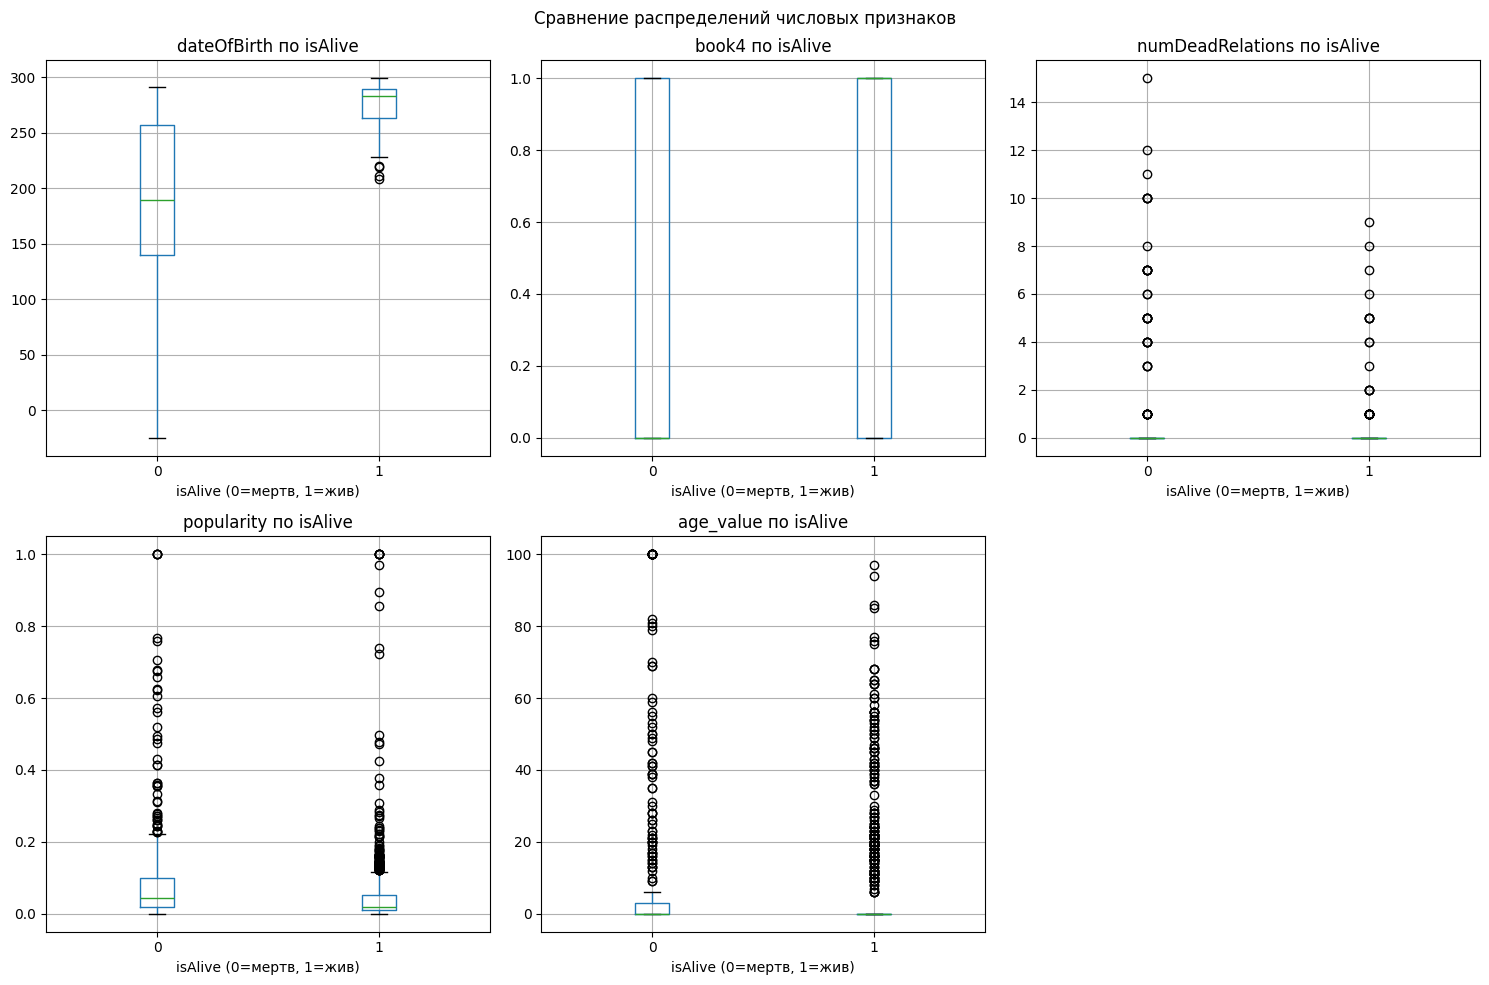

In [94]:
# Выделим числовые признаки
numeric_features = data.select_dtypes(include=[np.number]).columns.tolist()
if target in numeric_features:
    numeric_features.remove(target)

print("\n=== АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ ===\n")

if len(numeric_features) > 0:
    # Создадим DataFrame для анализа
    analysis_results = []

    for feature in numeric_features:
        # Разделяем данные по целевой переменной
        alive_vals = data[data[target] == 1][feature].dropna()
        dead_vals = data[data[target] == 0][feature].dropna()

        if len(alive_vals) > 0 and len(dead_vals) > 0:
            # t-тест для проверки значимости различий
            t_stat, p_value = stats.ttest_ind(alive_vals, dead_vals)

            # Расчет эффекта (разница средних)
            effect_size = alive_vals.mean() - dead_vals.mean()

            analysis_results.append({
                'Признак': feature,
                'Среднее (живые)': alive_vals.mean(),
                'Среднее (мертвые)': dead_vals.mean(),
                'Разница средних': effect_size,
                'p-value': p_value,
                'Значим (p<0.05)': p_value < 0.05
            })

    # Результаты анализа
    results_df = pd.DataFrame(analysis_results)
    results_df = results_df.sort_values('p-value')
    print("Статистическая значимость различий:")
    print(results_df.to_string(index=False))

    # Визуализация для топ-5 признаков
    top_features = results_df.head(5)['Признак'].tolist()

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()

    for i, feature in enumerate(top_features[:5]):
        data.boxplot(column=feature, by=target, ax=axes[i])
        axes[i].set_title(f'{feature} по isAlive')
        axes[i].set_xlabel('isAlive (0=мертв, 1=жив)')

    axes[5].axis('off')  # скрываем последний пустой график
    plt.suptitle('Сравнение распределений числовых признаков')
    plt.tight_layout()
    plt.show()


Корреляция признаков с isAlive:
isAlive             1.000000e+00
dateOfBirth         6.558810e-01
isAliveHeir         3.952847e-01
book4               2.840140e-01
isAliveFather       1.549826e-01
isAliveSpouse       1.223408e-01
age_no_data         1.136289e-01
book5               3.253064e-02
book3               1.842685e-02
isAliveMother       3.510833e-17
isMarried          -4.938068e-02
book2              -5.599775e-02
isNoble            -6.057220e-02
book1              -1.124682e-01
male               -1.482904e-01
age_value          -1.819384e-01
popularity         -1.941868e-01
numDeadRelations   -1.988762e-01
age                -3.111149e-01
Name: isAlive, dtype: float64


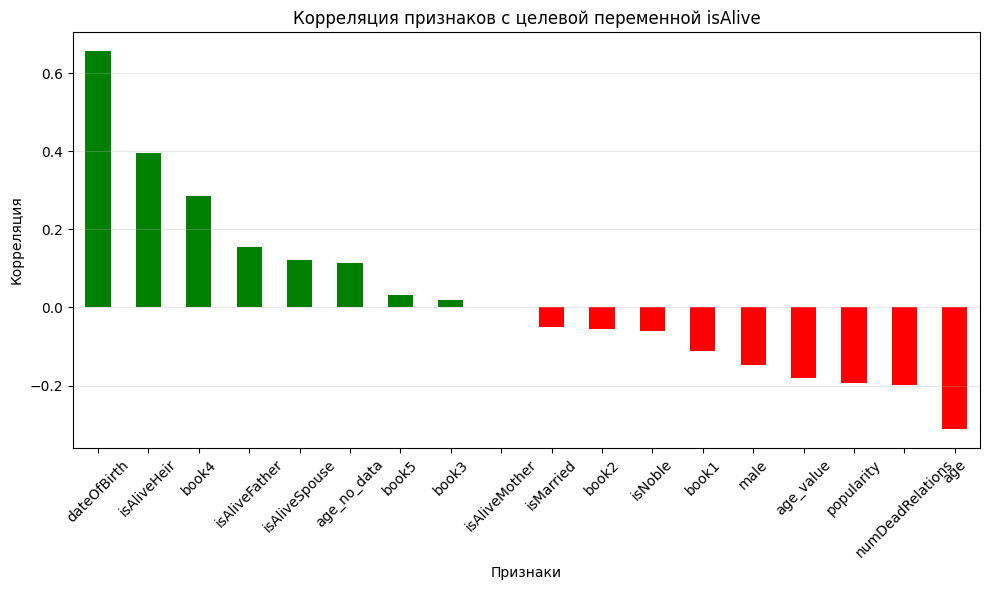

In [95]:
# Корреляция с целевой переменной
if len(numeric_features) > 0:
    correlations = data[numeric_features + [target]].corr()[target].sort_values(ascending=False)

    print("\nКорреляция признаков с isAlive:")
    print(correlations)

    # Визуализация
    plt.figure(figsize=(10, 6))
    correlations.drop(target).plot(kind='bar', color=['green' if x > 0 else 'red'
                                                       for x in correlations.drop(target)])
    plt.title('Корреляция признаков с целевой переменной isAlive')
    plt.xlabel('Признаки')
    plt.ylabel('Корреляция')
    plt.grid(True, alpha=0.3, axis='y')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


=== АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ===


Анализ признака: name
Пустые строки '': 0
NaN значения: 0

--- groupby() анализ ---
Всего категорий: 1557. Показываю топ-20:
                     mean  count  percent
name                                     
Zollo                 1.0      1     0.06
Abelar Hightower      1.0      1     0.06
Addam                 1.0      1     0.06
Addam Frey            1.0      1     0.06
Addam Marbrand        1.0      1     0.06
Ygon Farwynd          1.0      1     0.06
Xhondo                1.0      1     0.06
Wynton Stout          1.0      1     0.06
Wynafryd Manderly     1.0      1     0.06
Wynafrei Whent        1.0      1     0.06
Wylla                 1.0      1     0.06
Wyl the Whittler      1.0      1     0.06
Wun Weg Wun Dar Wun   1.0      1     0.06
Wulfe                 1.0      1     0.06
Wolmer                1.0      1     0.06
Willum                1.0      1     0.06
Willow Heddle         1.0      1     0.06
Albar Royce           1.0      1  

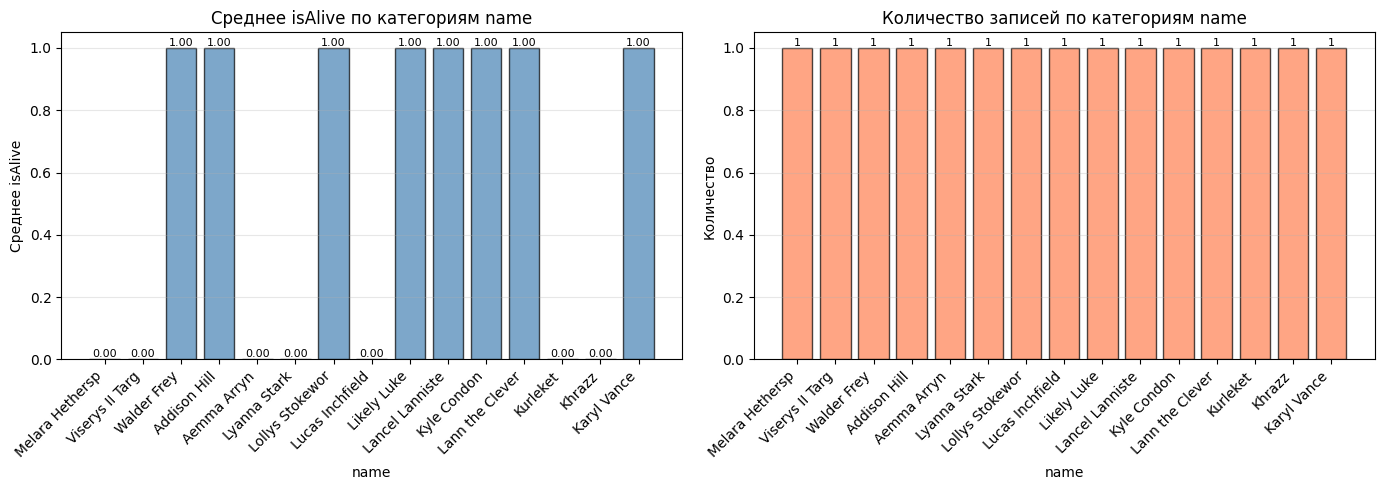


Анализ признака: title
Пустые строки '': 0
NaN значения: 840

--- groupby() анализ ---
Всего категорий: 196. Показываю топ-20:
                              mean  count  percent
title                                             
Acorn Hall                     1.0      1     0.06
Archmaester                    1.0     21     1.35
Ashford                        1.0      2     0.13
Banefort                       1.0      1     0.06
Big BucketThe Wull             1.0      1     0.06
Blackcrown                     1.0      2     0.13
Blackmont                      1.0      1     0.06
Blue Grace                     1.0      1     0.06
Broad Arch                     1.0      1     0.06
Brightwater                    1.0      1     0.06
BrotherProctor                 1.0      1     0.06
Brother                        1.0      3     0.19
Captain                        1.0      1     0.06
Castle Lychester               1.0      1     0.06
Coldwater Burn                 1.0      1     0.06
Comma

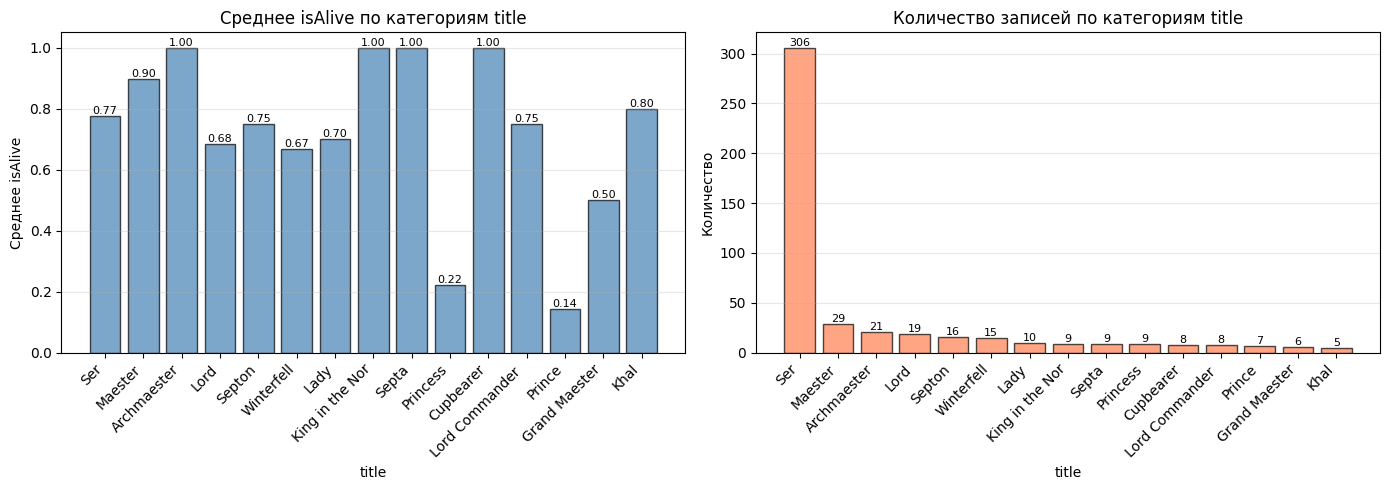


Анализ признака: culture
Пустые строки '': 0
NaN значения: 1069

--- groupby() анализ ---
Всего категорий: 52. Показываю топ-20:
                 mean  count  percent
culture                              
Andal             1.0      1     0.06
Andals            1.0      1     0.06
Braavos           1.0      1     0.06
Crannogmen        1.0      2     0.13
Ironmen           1.0      3     0.19
Dorne             1.0      1     0.06
First Men         1.0      2     0.13
Dornishmen        1.0      3     0.19
Lysene            1.0      2     0.13
Lhazarene         1.0      1     0.06
Ghiscaricari      1.0      1     0.06
Wildling          1.0      1     0.06
Summer Isles      1.0      4     0.26
Summer Islands    1.0      1     0.06
Summer Islander   1.0      1     0.06
Stormlands        1.0      4     0.26
Qohor             1.0      1     0.06
Qarth             1.0      1     0.06
Norvoshi          1.0      1     0.06
Lyseni            1.0      1     0.06

--- pivot_table анализ ---
Ошибка

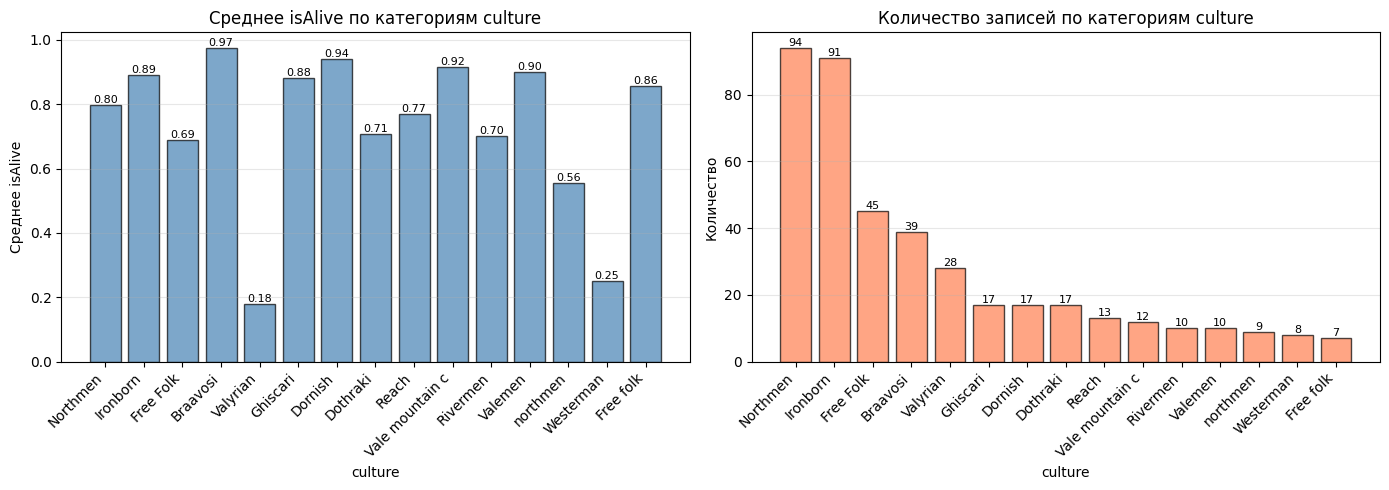


Анализ признака: mother
Пустые строки '': 0
NaN значения: 1539

--- groupby() анализ ---
                            mean  count  percent
mother                                          
Cassana Estermont       1.000000      1     0.06
Lady of House Sunderly  1.000000      1     0.06
NaN                     0.785575   1539    98.84
Cersei Lannister        0.500000      2     0.13
Alicent Hightower       0.000000      1     0.06
Betha Blackwood         0.000000      1     0.06
Alyssa Velaryon         0.000000      1     0.06
Catelyn Stark           0.000000      1     0.06
Alyssa Targaryen        0.000000      1     0.06
Daenaera Velaryon       0.000000      1     0.06
Mariah Martell          0.000000      1     0.06
Rhaenyra Targaryen      0.000000      2     0.13
Naerys Targaryen        0.000000      1     0.06
Rhaenys Targaryen       0.000000      1     0.06
Shaera Targaryen        0.000000      1     0.06
Valaena Velaryon        0.000000      1     0.06
Visenya Targaryen       0.00

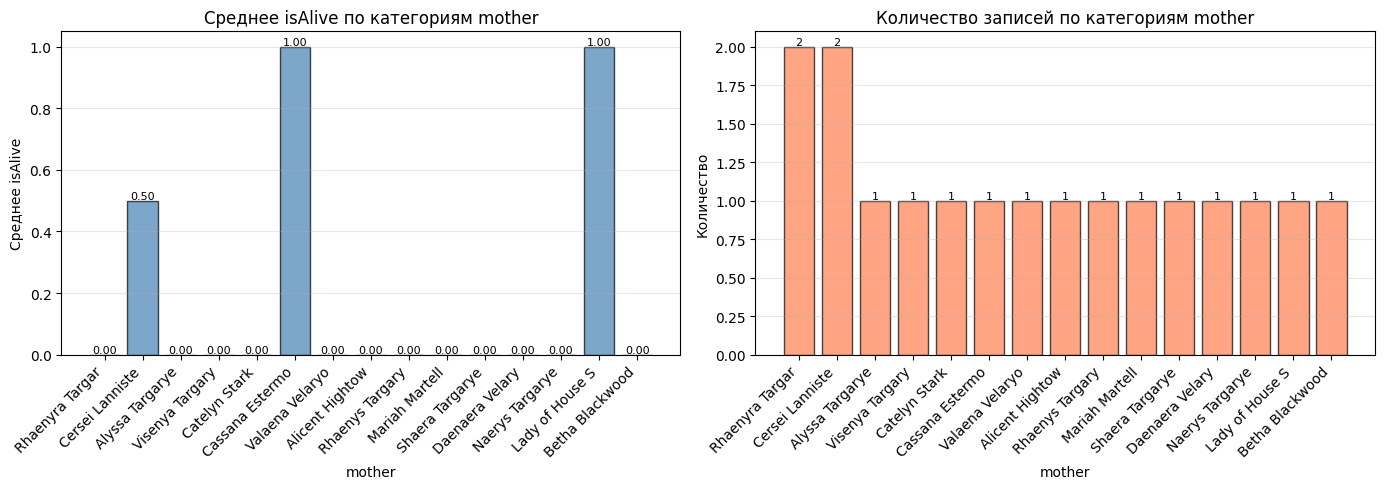


Анализ признака: father
Пустые строки '': 0
NaN значения: 1535

--- groupby() анализ ---
                            mean  count  percent
father                                          
Qhorwyn Hoare           1.000000      1     0.06
Quellon Greyjoy         1.000000      1     0.06
Tristifer IV Mudd       1.000000      1     0.06
Brandon Stark           1.000000      1     0.06
Steffon Baratheon       1.000000      1     0.06
NaN                     0.785668   1535    98.59
Robert Baratheon        0.500000      2     0.13
Aegon I Targaryen       0.000000      2     0.13
Aegon V Targaryen       0.000000      1     0.06
Aegon IV Targaryen      0.000000      1     0.06
Aegon III Targaryen     0.000000      1     0.06
Aenys I Targaryen       0.000000      1     0.06
Halleck Hoare           0.000000      1     0.06
Eddard Stark            0.000000      1     0.06
Daeron II Targaryen     0.000000      1     0.06
Daemon Targaryen        0.000000      2     0.13
Baelon Targaryen        0.00

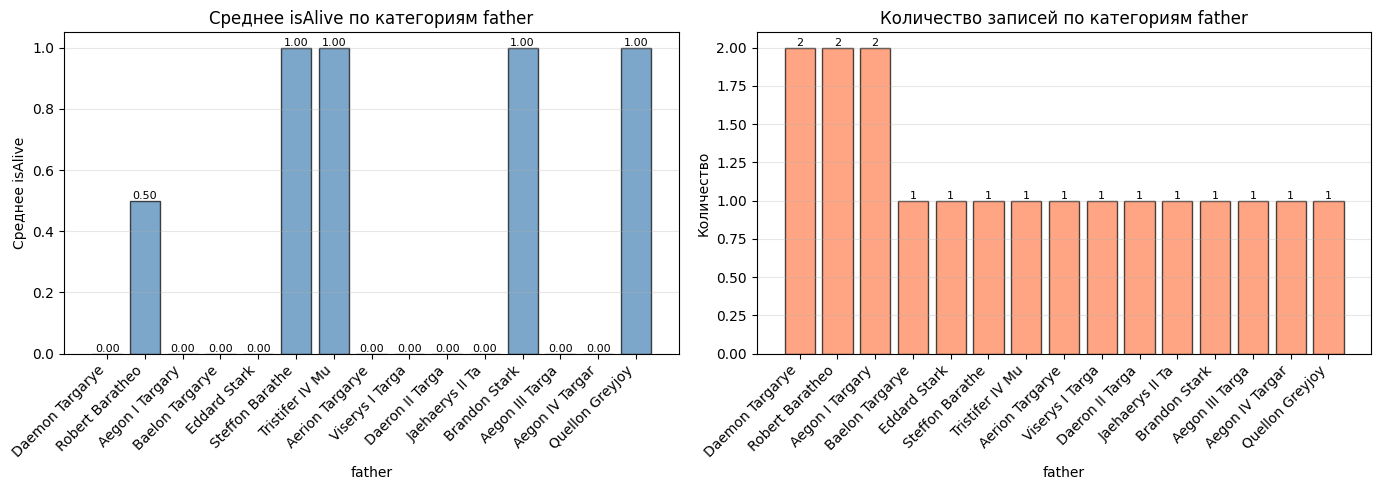


=== УПРОЩЕННЫЙ АНАЛИЗ (без pivot_table) ===


--- name ---
                   mean  count  std  percent
name                                        
Zollo               1.0      1  NaN     0.06
Abelar Hightower    1.0      1  NaN     0.06
Addam               1.0      1  NaN     0.06
Addam Frey          1.0      1  NaN     0.06
Addam Marbrand      1.0      1  NaN     0.06
Ygon Farwynd        1.0      1  NaN     0.06
Xhondo              1.0      1  NaN     0.06
Wynton Stout        1.0      1  NaN     0.06
Wynafryd Manderly   1.0      1  NaN     0.06
Wynafrei Whent      1.0      1  NaN     0.06

--- title ---
                       mean  count       std  percent
title                                                
NaN                0.800000    840  0.400238    53.95
Ser                0.774510    306  0.418589    19.65
Maester            0.896552     29  0.309934     1.86
Archmaester        1.000000     21  0.000000     1.35
Lord               0.684211     19  0.477567     1.22
Septon 

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

print("\n=== АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ===\n")

categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()
target = 'isAlive'

if len(categorical_features) > 0:
    for feature in categorical_features[:5]:  # Ограничим для наглядности
        print(f"\n{'='*50}")
        print(f"Анализ признака: {feature}")
        print('='*50)

        # ПРОВЕРКА И ОБРАБОТКА ПУСТЫХ СТРОК
        # Проверим, есть ли пустые строки
        empty_strings = (data[feature] == '').sum()
        nan_values = data[feature].isnull().sum()

        print(f"Пустые строки '': {empty_strings}")
        print(f"NaN значения: {nan_values}")

        # Создаем временную копию с обработанными пустыми строками
        temp_data = data.copy()

        # Заменяем пустые строки на специальную метку
        if empty_strings > 0:
            temp_data[feature] = temp_data[feature].replace('', 'EMPTY_STRING')
            print(f"Пустые строки заменены на 'EMPTY_STRING'")

        # СПОСОБ 1: Используем groupby() (более надежный)
        print(f"\n--- groupby() анализ ---")
        grouped = temp_data.groupby(feature, dropna=False)[target].agg(['mean', 'count'])
        grouped['percent'] = (grouped['count'] / len(temp_data) * 100).round(2)
        grouped = grouped.sort_values('mean', ascending=False)

        # Показываем все категории или топ-20, если их много
        if len(grouped) > 20:
            print(f"Всего категорий: {len(grouped)}. Показываю топ-20:")
            print(grouped.head(20))
        else:
            print(grouped)

        # СПОСОБ 2: Используем pivot_table (альтернативный)
        print(f"\n--- pivot_table анализ ---")
        try:
            pivot = pd.pivot_table(
                data=temp_data,
                values=target,
                index=feature,
                aggfunc=['mean', 'count'],
                dropna=False
            )

            # Добавим процент от общего числа
            total_count = len(temp_data)
            pivot_result = pd.DataFrame({
                'mean': pivot['mean'][feature],
                'count': pivot['count'][feature],
                'percent': (pivot['count'][feature] / total_count * 100).round(2)
            }).sort_values('mean', ascending=False)

            if len(pivot_result) > 20:
                print(pivot_result.head(20))
            else:
                print(pivot_result)

        except Exception as e:
            print(f"Ошибка при использовании pivot_table: {e}")
            print("Используем результаты groupby()")

        # Хи-квадрат тест для проверки зависимости
        if temp_data[feature].nunique(dropna=False) > 1:
            # Создаем таблицу сопряженности
            contingency_table = pd.crosstab(
                temp_data[feature].fillna('NaN'),
                temp_data[target],
                margins=False
            )

            # Проверяем, что таблица не слишком большая для теста
            if contingency_table.shape[0] > 1 and contingency_table.shape[1] > 1:
                chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
                print(f"\nХи-квадрат тест: p-value = {p_value:.4f}")
                print(f"Зависимость {'ЗНАЧИМА' if p_value < 0.05 else 'не значима'} (p<0.05)")

                # Крамер V для оценки силы связи
                n = contingency_table.sum().sum()
                phi2 = chi2 / n
                r, k = contingency_table.shape
                cramer_v = np.sqrt(phi2 / min(k-1, r-1))
                print(f"Крамер V (сила связи): {cramer_v:.3f}")
            else:
                print("\nНедостаточно категорий для Хи-квадрат теста")

        # Визуализация
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # График средних значений (топ-15 категорий по частоте)
        top_categories = temp_data[feature].value_counts().head(15).index

        if len(top_categories) > 0:
            mean_values = [temp_data[temp_data[feature] == cat][target].mean() for cat in top_categories]
            count_values = [temp_data[temp_data[feature] == cat][target].count() for cat in top_categories]

            # Средние значения
            bars1 = axes[0].bar(range(len(top_categories)), mean_values,
                                color='steelblue', edgecolor='black', alpha=0.7)
            axes[0].set_title(f'Среднее isAlive по категориям {feature}')
            axes[0].set_xlabel(feature)
            axes[0].set_ylabel('Среднее isAlive')
            axes[0].set_xticks(range(len(top_categories)))
            axes[0].set_xticklabels([str(cat)[:15] for cat in top_categories], rotation=45, ha='right')
            axes[0].grid(True, alpha=0.3, axis='y')

            # Добавим значения на столбцы
            for i, (bar, val) in enumerate(zip(bars1, mean_values)):
                height = bar.get_height()
                axes[0].text(bar.get_x() + bar.get_width()/2., height,
                            f'{val:.2f}', ha='center', va='bottom', fontsize=8)

            # Количество записей
            bars2 = axes[1].bar(range(len(top_categories)), count_values,
                                color='coral', edgecolor='black', alpha=0.7)
            axes[1].set_title(f'Количество записей по категориям {feature}')
            axes[1].set_xlabel(feature)
            axes[1].set_ylabel('Количество')
            axes[1].set_xticks(range(len(top_categories)))
            axes[1].set_xticklabels([str(cat)[:15] for cat in top_categories], rotation=45, ha='right')
            axes[1].grid(True, alpha=0.3, axis='y')

            # Добавим значения на столбцы
            for i, (bar, val) in enumerate(zip(bars2, count_values)):
                height = bar.get_height()
                axes[1].text(bar.get_x() + bar.get_width()/2., height,
                            f'{val}', ha='center', va='bottom', fontsize=8)

        plt.tight_layout()
        plt.show()

# АЛЬТЕРНАТИВНЫЙ ПРОСТОЙ СПОСОБ (если продолжаются ошибки)
print("\n=== УПРОЩЕННЫЙ АНАЛИЗ (без pivot_table) ===\n")

for feature in categorical_features[:5]:
    print(f"\n--- {feature} ---")

    # Простой groupby без сложных операций
    result = data.groupby(feature, dropna=False)[target].agg(['mean', 'count', 'std'])
    result['percent'] = (result['count'] / len(data) * 100).round(2)

    # Сортируем по частоте
    result = result.sort_values('count', ascending=False)

    print(result.head(10))  # Показываем топ-10 категорий


=== FEATURE IMPORTANCE (RANDOM FOREST) ===

Топ-15 наиболее важных признаков:
                feature  importance
             popularity    0.179425
           name_encoded    0.164892
          house_encoded    0.119134
                  book4    0.067872
          title_encoded    0.056170
        culture_encoded    0.045239
culture_grouped_encoded    0.036807
              age_value    0.035247
                    age    0.034968
            dateOfBirth    0.031906
                  book2    0.026404
                  book5    0.024619
                  book1    0.023916
                  book3    0.023005
                   male    0.021449


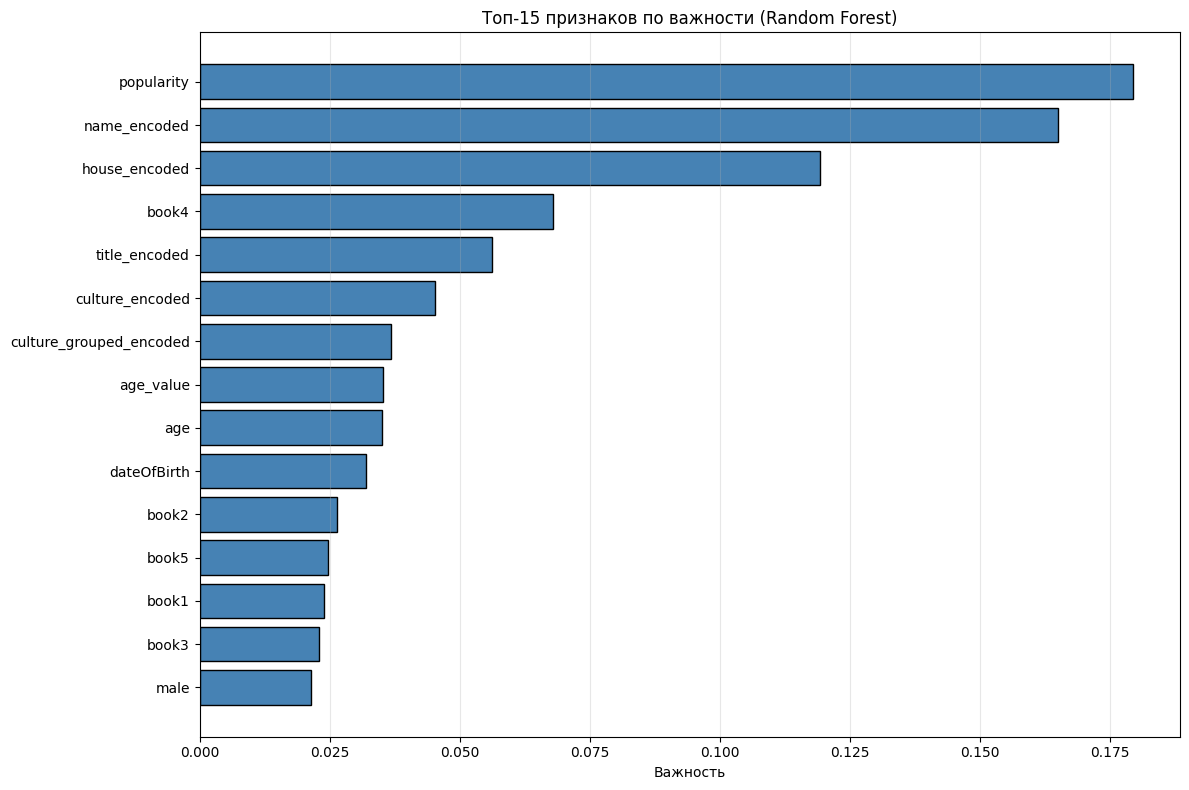

In [97]:
print("\n=== FEATURE IMPORTANCE (RANDOM FOREST) ===\n")

# Подготовим данные для модели
# Для простоты закодируем категориальные признаки
data_for_rf = data.copy()

# Кодируем категориальные признаки
le_dict = {}
for col in categorical_features:
    le = LabelEncoder()
    data_for_rf[col + '_encoded'] = le.fit_transform(data_for_rf[col].astype(str))
    le_dict[col] = le

# Выбираем признаки для модели
feature_cols = numeric_features + [col + '_encoded' for col in categorical_features]
X = data_for_rf[feature_cols].fillna(-999)  # заполняем пропуски для модели
y = data_for_rf[target]

# Обучаем Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X, y)

# Важность признаков
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("Топ-15 наиболее важных признаков:")
print(feature_importance.head(15).to_string(index=False))

# Визуализация
plt.figure(figsize=(12, 8))
plt.barh(feature_importance.head(15)['feature'],
         feature_importance.head(15)['importance'],
         color='steelblue', edgecolor='black')
plt.xlabel('Важность')
plt.title('Топ-15 признаков по важности (Random Forest)')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()


=== ВЗАИМНАЯ ИНФОРМАЦИЯ С ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ===

Топ-15 признаков по взаимной информации:
                feature  mutual_info
            dateOfBirth     0.050438
          house_encoded     0.049093
           name_encoded     0.035028
             popularity     0.032659
                  book4     0.031633
          isAliveMother     0.030465
                  book2     0.026959
                    age     0.026889
        culture_encoded     0.025601
          title_encoded     0.020848
         mother_encoded     0.020689
         spouse_encoded     0.014621
              age_value     0.011110
            isAliveHeir     0.010082
culture_grouped_encoded     0.007641

Сравнение топ-15 признаков по разным метрикам:
                feature  importance  mutual_info
                    age    0.034968     0.026889
              age_value    0.035247     0.011110
                  book1    0.023916     0.000000
                  book2    0.026404     0.026959
                  book3

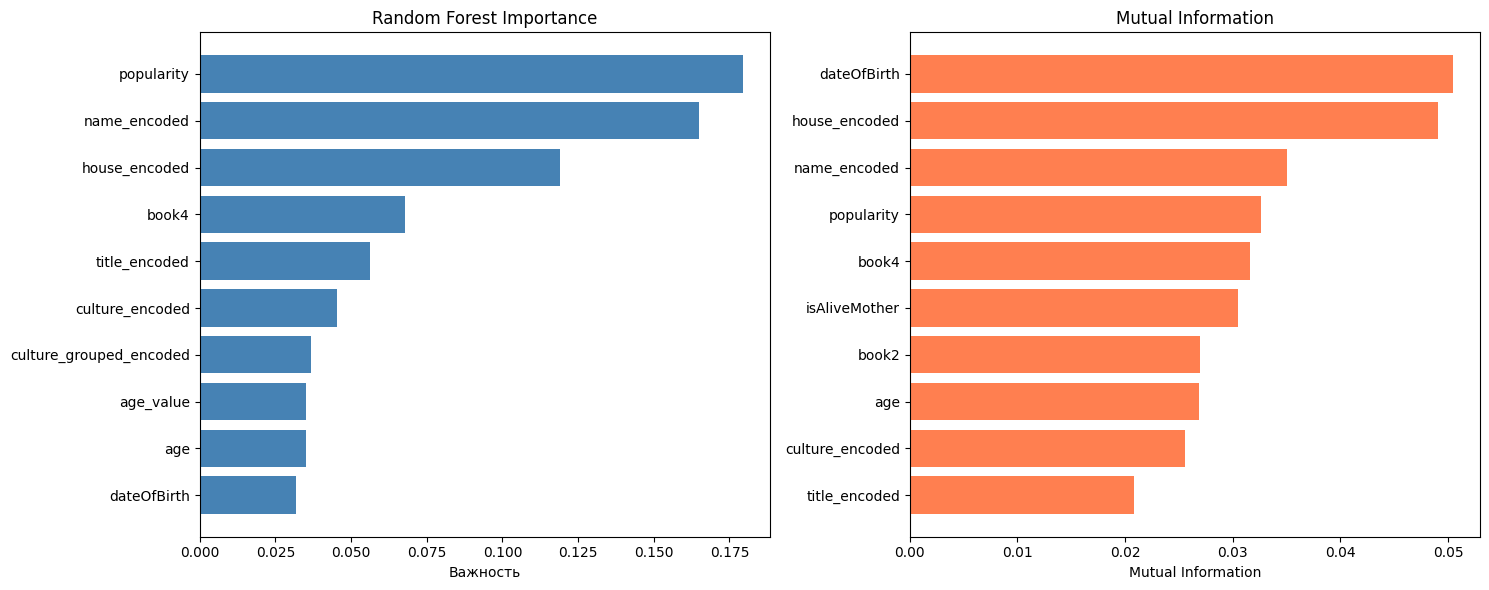

In [98]:
print("\n=== ВЗАИМНАЯ ИНФОРМАЦИЯ С ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ===\n")

# Mutual information показывает нелинейные зависимости
mi_scores = mutual_info_classif(X.fillna(-999), y, random_state=42)

mi_df = pd.DataFrame({
    'feature': feature_cols,
    'mutual_info': mi_scores
}).sort_values('mutual_info', ascending=False)

print("Топ-15 признаков по взаимной информации:")
print(mi_df.head(15).to_string(index=False))

# Сравнение с важностью из Random Forest
comparison = pd.merge(
    feature_importance.head(15),
    mi_df.head(15),
    on='feature',
    how='outer'
).fillna(0)

print("\nСравнение топ-15 признаков по разным метрикам:")
print(comparison.to_string(index=False))

# Визуализация сравнения
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Важность из Random Forest
axes[0].barh(feature_importance.head(10)['feature'],
             feature_importance.head(10)['importance'],
             color='steelblue')
axes[0].set_xlabel('Важность')
axes[0].set_title('Random Forest Importance')
axes[0].invert_yaxis()

# Mutual Information
axes[1].barh(mi_df.head(10)['feature'],
             mi_df.head(10)['mutual_info'],
             color='coral')
axes[1].set_xlabel('Mutual Information')
axes[1].set_title('Mutual Information')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


=== АНАЛИЗ ВЗАИМОДЕЙСТВИЙ ПРИЗНАКОВ ===

Доступные признаки (27): ['male', 'dateOfBirth', 'book1', 'book2', 'book3', 'book4', 'book5', 'isAliveMother', 'isAliveFather', 'isAliveHeir']...

Используем признаки для анализа: ['male', 'dateOfBirth', 'book1', 'book2', 'book3']

Структура дерева решений (первые уровни):


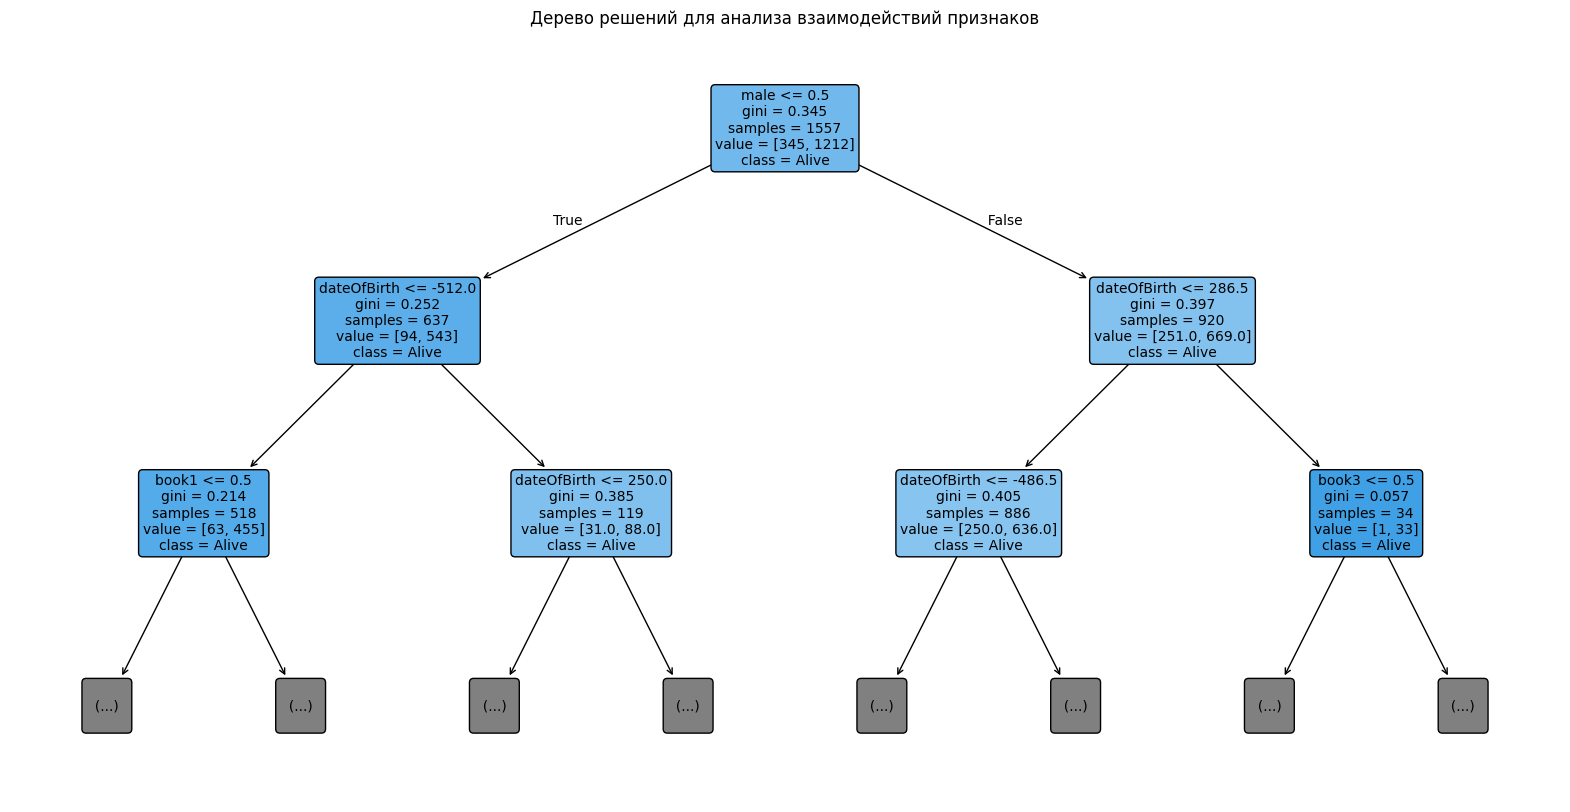


Важность признаков в дереве:
       feature  importance
1  dateOfBirth    0.759961
0         male    0.199498
2        book1    0.037781
4        book3    0.002760
3        book2    0.000000


In [99]:
print("\n=== АНАЛИЗ ВЗАИМОДЕЙСТВИЙ ПРИЗНАКОВ ===\n")

# Убедимся, что X и y определены
# X - матрица признаков, y - целевая переменная

# Получаем список всех доступных признаков
available_features = X.columns.tolist()
print(f"Доступные признаки ({len(available_features)}): {available_features[:10]}...")

# СПОСОБ 1: Используем признаки, которые точно есть в данных
# Выберем числовые признаки для анализа (они точно должны быть в X)
numeric_features_in_X = X.select_dtypes(include=[np.number]).columns.tolist()

if len(numeric_features_in_X) >= 2:
    # Возьмем первые 5 числовых признаков для анализа
    features_for_analysis = numeric_features_in_X[:5]
    print(f"\nИспользуем признаки для анализа: {features_for_analysis}")

    # Обучим простое дерево для анализа
    from sklearn.tree import DecisionTreeClassifier, plot_tree

    dt = DecisionTreeClassifier(max_depth=3, random_state=42)
    dt.fit(X[features_for_analysis], y)

    print("\nСтруктура дерева решений (первые уровни):")

    # Визуализация дерева
    plt.figure(figsize=(20, 10))
    plot_tree(dt, feature_names=features_for_analysis, filled=True,
              class_names=['Dead', 'Alive'], rounded=True, fontsize=10,
              max_depth=2)  # Ограничим глубину отображения
    plt.title('Дерево решений для анализа взаимодействий признаков')
    plt.show()

    # Важность признаков в дереве
    importance_df = pd.DataFrame({
        'feature': features_for_analysis,
        'importance': dt.feature_importances_
    }).sort_values('importance', ascending=False)

    print("\nВажность признаков в дереве:")
    print(importance_df)

else:
    print("Недостаточно числовых признаков для анализа")


=== ИТОГОВЫЙ АНАЛИЗ ===

Топ-10 наиболее влиятельных признаков (по сумме метрик):
                Признак  RandomForest_Importance  Mutual_Information  Correlation
             popularity                 0.179425            0.032659    -0.194187
           name_encoded                 0.164892            0.035028          NaN
          house_encoded                 0.119134            0.049093          NaN
                  book4                 0.067872            0.031633     0.284014
          title_encoded                 0.056170            0.020848          NaN
        culture_encoded                 0.045239            0.025601          NaN
culture_grouped_encoded                 0.036807            0.007641          NaN
              age_value                 0.035247            0.011110    -0.181938
                    age                 0.034968            0.026889    -0.311115
            dateOfBirth                 0.031906            0.050438     0.655881


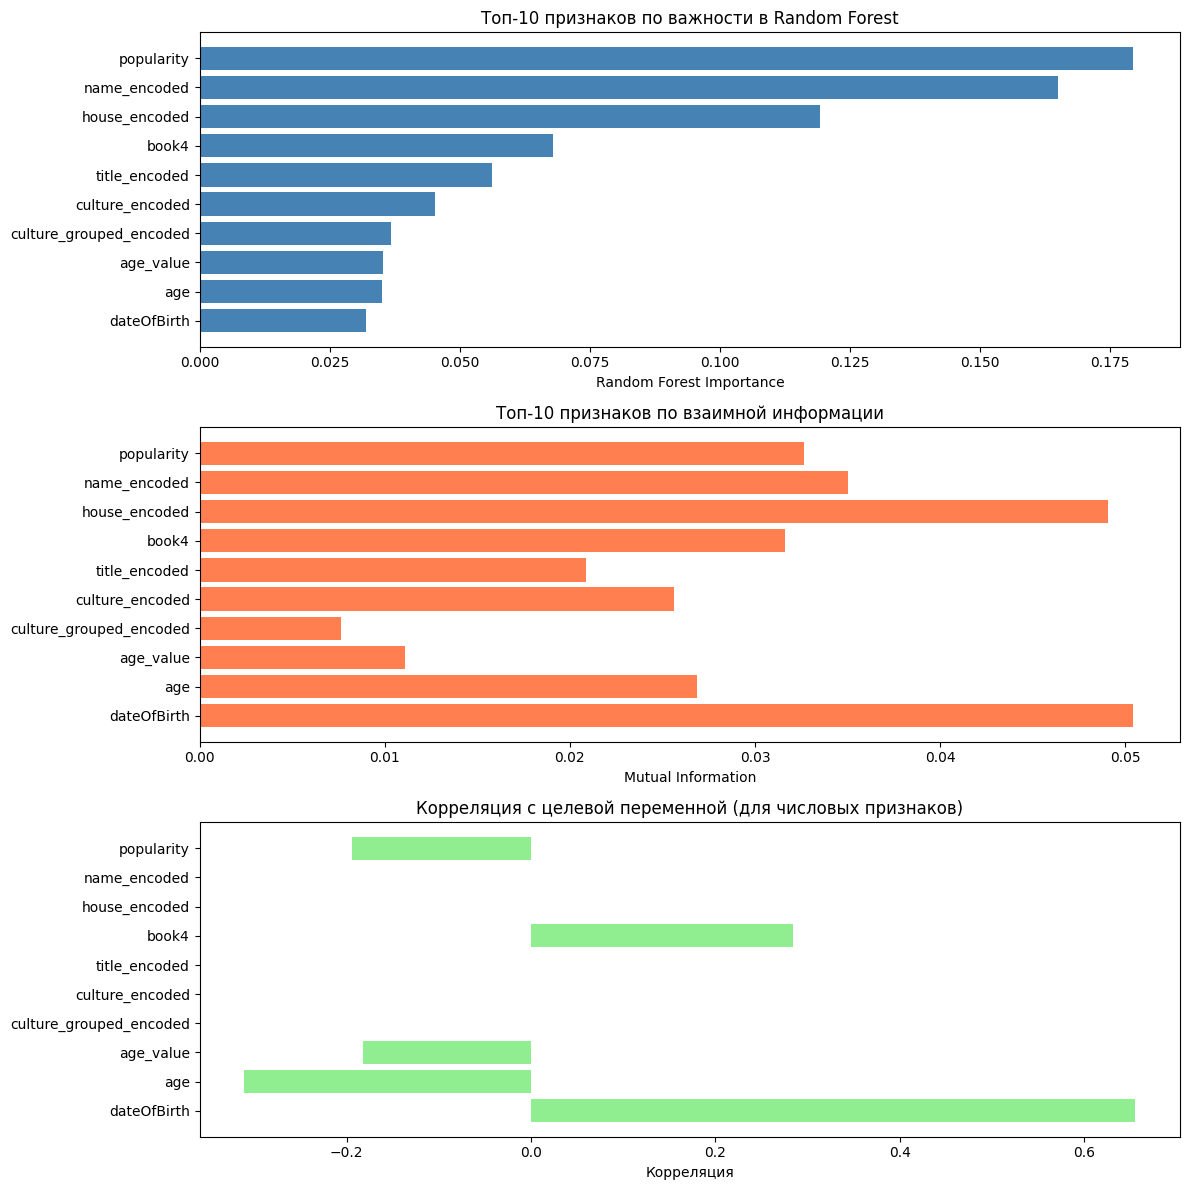


=== КЛЮЧЕВЫЕ ВЫВОДЫ ===

1. Наиболее важные признаки для предсказания выживаемости:
   • popularity: важность 0.179
   • name_encoded: важность 0.165
   • house_encoded: важность 0.119
   • book4: важность 0.068
   • title_encoded: важность 0.056

2. Рекомендации по использованию признаков:
   • Включите в модель все признаки из топ-10
   • Обратите внимание на признаки с высокой корреляцией между собой
   • Для категориальных признаков используйте one-hot encoding
   • Проверьте устойчивость важности признаков на кросс-валидации


In [100]:
print("\n=== ИТОГОВЫЙ АНАЛИЗ ===\n")

# Соберем все результаты в один DataFrame
summary = pd.DataFrame({
    'Признак': feature_cols,
    'RandomForest_Importance': rf.feature_importances_,
    'Mutual_Information': mi_scores
})

# Добавим корреляцию для числовых признаков
for feature in numeric_features:
    if feature in summary['Признак'].values:
        corr_val = data[feature].corr(data[target])
        summary.loc[summary['Признак'] == feature, 'Correlation'] = corr_val

summary = summary.sort_values('RandomForest_Importance', ascending=False)

print("Топ-10 наиболее влиятельных признаков (по сумме метрик):")
top10 = summary.head(10)
print(top10.to_string(index=False))

# Визуализация итогов
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

# Random Forest Importance
axes[0].barh(top10['Признак'], top10['RandomForest_Importance'], color='steelblue')
axes[0].set_xlabel('Random Forest Importance')
axes[0].set_title('Топ-10 признаков по важности в Random Forest')
axes[0].invert_yaxis()

# Mutual Information
axes[1].barh(top10['Признак'], top10['Mutual_Information'], color='coral')
axes[1].set_xlabel('Mutual Information')
axes[1].set_title('Топ-10 признаков по взаимной информации')
axes[1].invert_yaxis()

# Корреляция (для числовых)
axes[2].barh(top10['Признак'], top10['Correlation'].fillna(0), color='lightgreen')
axes[2].set_xlabel('Корреляция')
axes[2].set_title('Корреляция с целевой переменной (для числовых признаков)')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

print("\n=== КЛЮЧЕВЫЕ ВЫВОДЫ ===\n")
print("1. Наиболее важные признаки для предсказания выживаемости:")
for i, row in top10.head(5).iterrows():
    print(f"   • {row['Признак']}: важность {row['RandomForest_Importance']:.3f}")

print("\n2. Рекомендации по использованию признаков:")
print("   • Включите в модель все признаки из топ-10")
print("   • Обратите внимание на признаки с высокой корреляцией между собой")
print("   • Для категориальных признаков используйте one-hot encoding")
print("   • Проверьте устойчивость важности признаков на кросс-валидации")

**Задание 1.9.** Создайте переменные `X`, которая будет хранить только значения признаков, которые вы отобрали для включения в модель, и `y`, которая будет хранить только значения целевой переменной.

In [101]:
import pandas as pd
import numpy as np

# Предполагаем, что data - это наш обработанный датасет
# target = 'isAlive' - наша целевая переменная

# СПОСОБ 1: Если у вас есть список отобранных признаков
selected_features = [
    # Добавьте сюда названия признаков, которые вы отобрали
    # Например:
    'age_value',
    'age_no_data',
    'culture_grouped'

    # ... другие признаки
]

# Создаем X с только отобранными признаками
X = data[selected_features].copy()

# Создаем y с целевой переменной
y = data['isAlive'].copy()

print("=== РЕЗУЛЬТАТ ===")
print(f"Размер X: {X.shape}")
print(f"Размер y: {y.shape}")
print(f"\nПризнаки в X ({len(selected_features)}):")
print(X.columns.tolist())
print(f"\nПервые 5 строк X:")
print(X.head())
print(f"\nПервые 5 значений y:")
print(y.head())

=== РЕЗУЛЬТАТ ===
Размер X: (1557, 3)
Размер y: (1557,)

Признаки в X (3):
['age_value', 'age_no_data', 'culture_grouped']

Первые 5 строк X:
      age_value  age_no_data       culture_grouped
S.No                                              
1           0.0            1       culture_no_data
2          97.0            0  the Isles and Rivers
3           0.0            1       culture_no_data
4          23.0            0       culture_no_data
5          29.0            0                 Dorne

Первые 5 значений y:
S.No
1    0
2    1
3    1
4    0
5    1
Name: isAlive, dtype: int64


**Задание 1.10.** Разделите датасет обучащую и валидационные части (train и val) при помощи функции `train_test_split` (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [102]:
from sklearn.model_selection import train_test_split

In [103]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,       # Можно изменить размер валидационной выборки
    random_state=42,     # Обеспечивает повторяемость результатов
    stratify=y           # Рекомендуется для сохранения пропорций классов
)

## Часть 2. Обучение моделей

В данной части домашнего задания, мы хотим научиться обучать модели для задачи классификации на наших данных.

**Задание 2.1.**


Вы можете работать с одной из предложенных моделей из библиотеки `sklearn`
* LogisticRegression
* RandomForestClassifier
* AdaBoostClassifier
* GaussianProcessClassifier
* GaussianNB
* KNeighborsClassifier
* SVC
* DecisionTreeClassifier


Однако в этом домашнем задании мы предлагаем выбрать и поработать с моделью `LogisticRegression`.

In [104]:
from sklearn.linear_model import LogisticRegression


Импортируйте остальные модели из библиотеки `sklearn`. Чтобы понять как это сделать, воспользуйтесь официальный документацией `sklearn` $→$ [тык](https://scikit-learn.org/dev/user_guide.html). По ключевому названию модели, вы сможете найти необходимую информацию о том, как можно импортировать модель из библиотеки.

**Задание 2.2.** Обучите модель и сделайте предсказание на тестовой выборке

В качестве примера, обучим модель `LogisticRegression` и сделаем на ней предсказания на тестовой выборке.

In [115]:

# Задание 2.2. Обучите модель и сделайте предсказание на тестовой выборке
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Шаг 1. создание модели
model = LogisticRegression(random_state=42, max_iter=1000)

# Шаг 2. обучение модели
model.fit(X_train, y_train)

# Шаг 3. Предсказание на валидационных данных
y_pred = model.predict(X_val)

# Оценка качества
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_val, y_pred)
print(f"Точность LogisticRegression: {accuracy:.4f}")

Точность LogisticRegression: 0.7788


## Часть 3. Оцените качество моделей

Вам необходимо познакомиться с метриками задачи классификации из sklearn. Оцените все модели и выберите лучшую по метрике качества Accuracy.

С метриками классификации вы можете ознакомиться в [Yandex ML Book](https://education.yandex.ru/handbook/ml/article/metriki-klassifikacii-i-regressii).

Для простоты в данном домашнем задании мы будем работать с самой базовой метрикой для задачи классификации - accuracy.

**Задание 3.1.** Вам необходимо посчитать метрику для всех моделей и выбрать лучшую модель.

Сначала импортируем необходимую функцию из библиотеки sklearn для подсчета accuracy.

In [106]:
from sklearn.metrics import accuracy_score

В качестве примера, посчитаем метрику accuracy для модели `LogisticRegression`

In [116]:
# Часть 3. Оцените качество моделей
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Словарь с моделями
models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RandomForestClassifier': RandomForestClassifier(random_state=42),
    'AdaBoostClassifier': AdaBoostClassifier(random_state=42),
    'SVC': SVC(random_state=42),
    'DecisionTreeClassifier': DecisionTreeClassifier(random_state=42),
    'KNeighborsClassifier': KNeighborsClassifier(),
    'GaussianNB': GaussianNB()
}

# Словарь для результатов
results = {}

# Обучение и оценка каждой модели
for model_name, model in models.items():
    print(f"\nОбучение модели: {model_name}")

    # Обучение
    model.fit(X_train, y_train)

    # Предсказание
    y_pred = model.predict(X_val)

    # Оценка
    accuracy = accuracy_score(y_val, y_pred)
    results[model_name] = accuracy
    print(f"Accuracy для {model_name}: {accuracy:.4f}")

# Выбор лучшей модели
best_model_name = max(results, key=results.get)
best_accuracy = results[best_model_name]

print("\n" + "="*50)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ:")
print("="*50)
for model_name, accuracy in results.items():
    print(f"{model_name}: {accuracy:.4f}")

print(f"\n🏆 Лучшая модель: {best_model_name} с accuracy = {best_accuracy:.4f}")


Обучение модели: LogisticRegression
Accuracy для LogisticRegression: 0.7788

Обучение модели: RandomForestClassifier
Accuracy для RandomForestClassifier: 0.7756

Обучение модели: AdaBoostClassifier
Accuracy для AdaBoostClassifier: 0.7853

Обучение модели: SVC
Accuracy для SVC: 0.7885

Обучение модели: DecisionTreeClassifier
Accuracy для DecisionTreeClassifier: 0.7500

Обучение модели: KNeighborsClassifier
Accuracy для KNeighborsClassifier: 0.7308

Обучение модели: GaussianNB
Accuracy для GaussianNB: 0.7179

ИТОГОВЫЕ РЕЗУЛЬТАТЫ:
LogisticRegression: 0.7788
RandomForestClassifier: 0.7756
AdaBoostClassifier: 0.7853
SVC: 0.7885
DecisionTreeClassifier: 0.7500
KNeighborsClassifier: 0.7308
GaussianNB: 0.7179

🏆 Лучшая модель: SVC с accuracy = 0.7885


Возможно, вы решите вернуться на несколько шагов и попробовать другие варианты преобразования и подбора признаков в модель. **Выберите** лучшую модель.

### Тестовый датасет

В самом начале нашего домашнего задания мы скачивали тестовый датасет. Загрузите его в Pandas DataFrame при помощи функции read_csv

In [108]:
data_test = pd.read_csv('game_of_thrones_test.csv')

По аналогии с тем, как мы работали с обучающим датасетом, давайте посмотрим в тестовом датасете на статистики признаков с разными типами данных  

АНАЛИЗ ТЕСТОВОГО ДАТАСЕТА

1. ОСНОВНАЯ ИНФОРМАЦИЯ:
Размерность: (389, 25)
Колонки: ['S.No', 'name', 'title', 'male', 'culture', 'dateOfBirth', 'mother', 'father', 'heir', 'house', 'spouse', 'book1', 'book2', 'book3', 'book4', 'book5', 'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse', 'isMarried', 'isNoble', 'age', 'numDeadRelations', 'popularity']
Типы данных:
S.No                  int64
name                 object
title                object
male                  int64
culture              object
dateOfBirth         float64
mother               object
father               object
heir                 object
house                object
spouse               object
book1                 int64
book2                 int64
book3                 int64
book4                 int64
book5                 int64
isAliveMother       float64
isAliveFather       float64
isAliveHeir         float64
isAliveSpouse       float64
isMarried             int64
isNoble               int64
age  

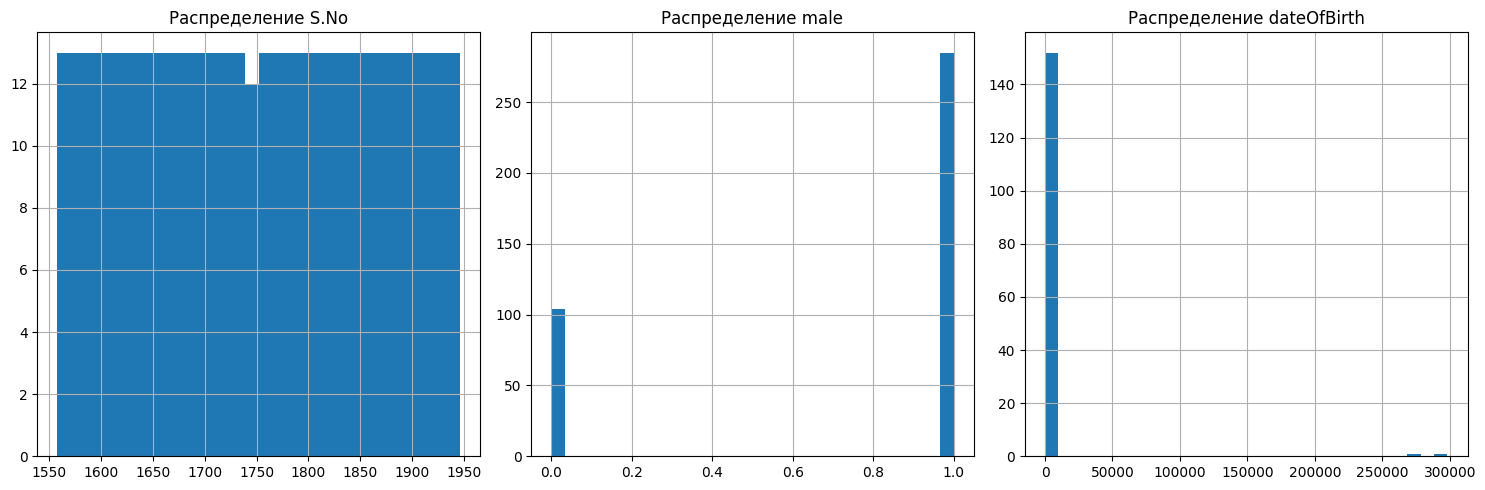

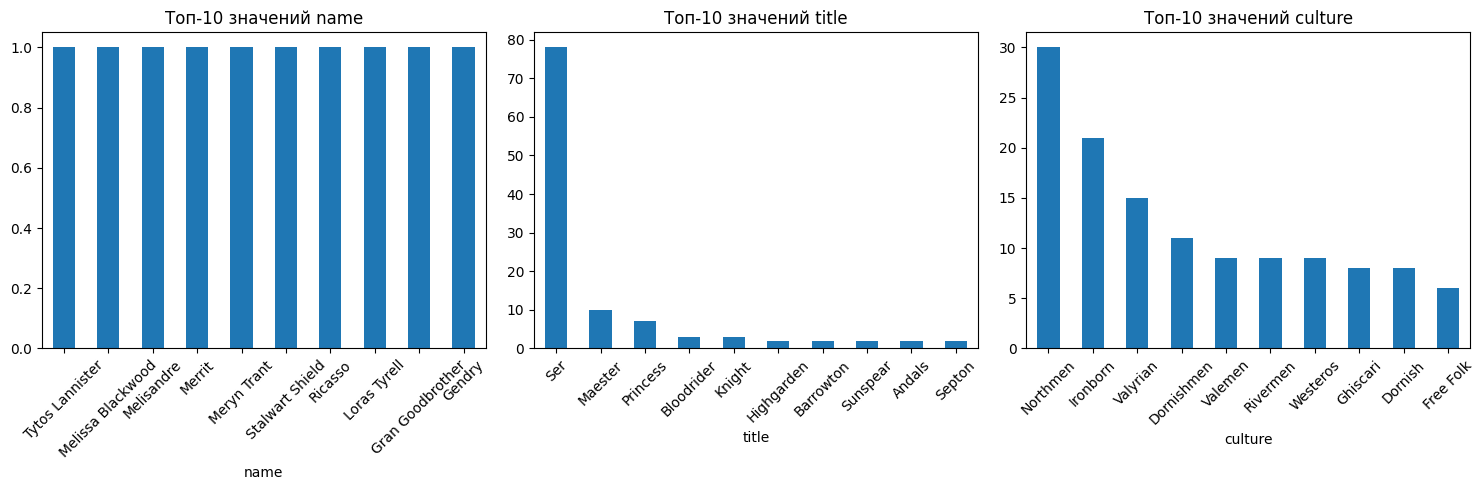


АНАЛИЗ ЗАВЕРШЕН


In [109]:


print("="*60)
print("АНАЛИЗ ТЕСТОВОГО ДАТАСЕТА")
print("="*60)

# 1. Базовая информация
print("\n1. ОСНОВНАЯ ИНФОРМАЦИЯ:")
print(f"Размерность: {data_test.shape}")
print(f"Колонки: {list(data_test.columns)}")
print(f"Типы данных:\n{data_test.dtypes}")

# 2. Пропущенные значения
print("\n2. ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:")
missing_data = data_test.isnull().sum()
missing_percent = (missing_data / len(data_test)) * 100
missing_df = pd.DataFrame({
    'Пропущено': missing_data,
    'Процент': missing_percent
})
print(missing_df[missing_df['Пропущено'] > 0])

# 3. Поиск аномалий в числовых признаках
print("\n3. ПОИСК АНОМАЛИЙ В ЧИСЛОВЫХ ПРИЗНАКАХ:")

# Возраст (отрицательные значения)
negative_age = data_test.loc[data_test['age'] < 0]
if len(negative_age) > 0:
    print(f"\nНайдены записи с отрицательным возрастом: {len(negative_age)}")
    print(negative_age[['age']].head())
else:
    print("\n✓ Отрицательных значений возраста нет")

# Возраст (слишком большие значения)
old_age = data_test.loc[data_test['age'] > 100]
if len(old_age) > 0:
    print(f"\nНайдены записи с возрастом > 100 лет: {len(old_age)}")
    print(old_age[['age']].head())
else:
    print("✓ Возраст > 100 лет не найден")

# Проверка возраста по дате рождения (если есть обе колонки)
if 'age' in data_test.columns and 'birth_date' in data_test.columns:
    # Конвертируем дату рождения в возраст (примерно)
    try:
        current_year = 2026
        data_test['birth_year'] = pd.to_datetime(data_test['birth_date'], errors='coerce').dt.year
        data_test['calculated_age'] = current_year - data_test['birth_year']
        age_mismatch = data_test.loc[abs(data_test['age'] - data_test['calculated_age']) > 2]
        print(f"\nНесоответствие возраста и даты рождения: {len(age_mismatch)} записей")
    except:
        print("\nНе удалось обработать даты рождения")

# 4. Статистика по категориальным признакам
print("\n4. АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ:")
categorical_cols = data_test.select_dtypes(include=['object']).columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(f"Уникальных значений: {data_test[col].nunique()}")
    print(f"Топ-5 наиболее частых значений:")
    print(data_test[col].value_counts().head())

# 5. Сравнение с обучающим датасетом
print("\n5. СРАВНЕНИЕ С ОБУЧАЮЩИМ ДАТАСЕТОМ:")
print(f"Тестовый датасет: {len(data_test)} записей")
print(f"Обучающий датасет: {len(X_train) + len(X_val)} записей (если доступно)")

# Проверка соответствия категорий в тестовом и обучающем датасетах
# (если у нас есть доступ к обучающему датасету)
try:
    for col in categorical_cols:
        if col in X_train.columns:
            train_categories = set(X_train[col].unique())
            test_categories = set(data_test[col].unique())
            new_categories = test_categories - train_categories
            if new_categories:
                print(f"\nВ колонке '{col}' есть новые категории в тестовом датасете:")
                print(f"Новые значения: {new_categories}")
            else:
                print(f"\n✓ Колонка '{col}' содержит только известные категории")
except:
    print("Нет доступа к обучающему датасету для сравнения")

# 6. Дескриптивная статистика для числовых признаков
print("\n6. ДЕСКРИПТИВНАЯ СТАТИСТИКА:")
numeric_cols = data_test.select_dtypes(include=[np.number]).columns
print(data_test[numeric_cols].describe())

# 7. Проверка дубликатов
print("\n7. ПРОВЕРКА ДУБЛИКАТОВ:")
duplicates = data_test.duplicated().sum()
print(f"Найдено дубликатов: {duplicates}")

# 8. Визуализация распределений (опционально)
try:
    import matplotlib.pyplot as plt
    import seaborn as sns

    # Для числовых признаков
    if len(numeric_cols) > 0:
        fig, axes = plt.subplots(1, min(3, len(numeric_cols)), figsize=(15, 5))
        if len(numeric_cols) == 1:
            axes = [axes]
        for i, col in enumerate(numeric_cols[:3]):
            data_test[col].hist(ax=axes[i], bins=30)
            axes[i].set_title(f'Распределение {col}')
        plt.tight_layout()
        plt.show()

    # Для категориальных признаков
    if len(categorical_cols) > 0:
        fig, axes = plt.subplots(1, min(3, len(categorical_cols)), figsize=(15, 5))
        if len(categorical_cols) == 1:
            axes = [axes]
        for i, col in enumerate(categorical_cols[:3]):
            data_test[col].value_counts().head(10).plot(kind='bar', ax=axes[i])
            axes[i].set_title(f'Топ-10 значений {col}')
            axes[i].tick_params(axis='x', rotation=45)
        plt.tight_layout()
        plt.show()
except:
    print("\nДля визуализации установите matplotlib и seaborn")

print("\n" + "="*60)
print("АНАЛИЗ ЗАВЕРШЕН")
print("="*60)

In [110]:
#Вы можете аккуратно поправить тестовые данные, воспользовавшись, например следующим кодом:
data_test.loc[1685, 'dateOfBirth'] = 278.
# замены в строке 1685: dateOfBirth -> 278. и age -> 0.
# замены в строке 1869: dateOfBirth -> 299. и age -> 0.

Преобразуйте признаки в тестовом датасете по тому же пайплайну, как вы преобразовывали обучающие данные. Примените вашу лучшую модель на тестовом датасете для получения прогноза целевой переменной `isAlive`

In [122]:
# Преобразуйте признаки в тестовом датасете и сделайте предсказания
print("\n" + "="*60)
print("ПРЕДСКАЗАНИЕ НА ТЕСТОВОМ ДАТАСЕТЕ")
print("="*60)

# 1. Загружаем тестовый датасет
data_test = pd.read_csv('game_of_thrones_test.csv', index_col='S.No')

# 2. Исправляем аномалии
data_test.loc[1685, 'dateOfBirth'] = 278.
data_test.loc[1685, 'age'] = 0.
data_test.loc[1869, 'dateOfBirth'] = 299.
data_test.loc[1869, 'age'] = 0.
print("✓ Аномалии исправлены")

# 3. Применяем те же преобразования, что и к обучающим данным
# Создаем признаки age_value и age_no_data
data_test['age_value'] = data_test['age'].fillna(0)
data_test['age_no_data'] = [1 if pd.isna(x) else 0 for x in data_test['age']]

# Создаем boolDeadRelations
if 'numDeadRelations' in data_test.columns:
    data_test['boolDeadRelations'] = (data_test['numDeadRelations'] > 0).astype(int)

# Создаем popularity_log
if 'popularity' in data_test.columns:
    optimal_M = 100
    data_test['popularity_log'] = np.log10(data_test['popularity'] * optimal_M + 1)

# Группировка culture
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans', 'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen', 'meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']
}

# Инвертируем словарь
cultures_grouped_inverted = {}
for category, culture_list in cultures_grouped.items():
    for culture in culture_list:
        cultures_grouped_inverted[culture] = category

# Применяем группировку
data_test['culture_grouped'] = data_test['culture'].str.lower().map(cultures_grouped_inverted)
data_test['culture_grouped'] = data_test['culture_grouped'].fillna('culture_no_data')

# 4. ВАЖНО: Добавляем новые признаки в обучающие данные
print("\nДобавляем новые признаки в обучающие данные...")

# Добавляем boolDeadRelations в исходные данные, если их там нет
if 'boolDeadRelations' not in data.columns and 'numDeadRelations' in data.columns:
    data['boolDeadRelations'] = (data['numDeadRelations'] > 0).astype(int)
    print("- boolDeadRelations добавлен")

# Добавляем popularity_log в исходные данные, если их там нет
if 'popularity_log' not in data.columns and 'popularity' in data.columns:
    optimal_M = 100
    data['popularity_log'] = np.log10(data['popularity'] * optimal_M + 1)
    print("- popularity_log добавлен")

# Обновляем X_train с новыми признаками
print("\nОбновляем X_train...")
for col in ['boolDeadRelations', 'popularity_log', 'age_value', 'age_no_data', 'culture_grouped']:
    if col in data.columns and col not in X_train.columns:
        X_train[col] = data.loc[X_train.index, col]
        print(f"  - {col} добавлен в X_train")

# Обновляем X_val
for col in ['boolDeadRelations', 'popularity_log', 'age_value', 'age_no_data', 'culture_grouped']:
    if col in data.columns and col not in X_val.columns:
        X_val[col] = data.loc[X_val.index, col]
        print(f"  - {col} добавлен в X_val")

# 5. Выбираем общие признаки для теста
common_features = [col for col in X_train.columns if col in data_test.columns]
print(f"\nОбщие признаки: {common_features}")

# Создаем X_test
X_test = data_test[common_features].copy()
print(f"Размер X_test: {X_test.shape}")

# 6. Обрабатываем пропуски
for col in X_test.columns:
    if X_test[col].dtype == 'object':
        X_test[col] = X_test[col].fillna('missing')
    else:
        X_test[col] = X_test[col].fillna(0)

# 7. ПРИНУДИТЕЛЬНОЕ ПРЕОБРАЗОВАНИЕ ВСЕХ ПРИЗНАКОВ В ЧИСЛОВОЙ ФОРМАТ
print("\n" + "="*60)
print("ПРИНУДИТЕЛЬНОЕ ПРЕОБРАЗОВАНИЕ В ЧИСЛОВОЙ ФОРМАТ")
print("="*60)

# Проверяем типы данных
print("\nТипы данных ДО преобразования:")
print(f"X_train: {X_train.dtypes.value_counts().to_dict()}")
print(f"X_test: {X_test.dtypes.value_counts().to_dict()}")

# Находим все строковые колонки в X_train и X_test
string_cols_train = X_train.select_dtypes(include=['object']).columns.tolist()
string_cols_test = X_test.select_dtypes(include=['object']).columns.tolist()
all_string_cols = list(set(string_cols_train + string_cols_test))

print(f"\nНайдены строковые колонки: {all_string_cols}")

if len(all_string_cols) > 0:
    from sklearn.preprocessing import LabelEncoder

    for col in all_string_cols:
        print(f"\n  Обработка колонки: {col}")

        # Создаем кодировщик
        le = LabelEncoder()

        # Собираем все значения из train и test
        train_vals = X_train[col].astype(str) if col in X_train.columns else pd.Series([])
        test_vals = X_test[col].astype(str) if col in X_test.columns else pd.Series([])
        all_vals = pd.concat([train_vals, test_vals]).unique()

        # Обучаем кодировщик
        le.fit(all_vals)
        print(f"    Уникальных значений: {len(le.classes_)}")

        # Преобразуем train
        if col in X_train.columns:
            X_train[col] = le.transform(X_train[col].astype(str))
            print(f"    X_train преобразован")

        # Преобразуем test
        if col in X_test.columns:
            X_test[col] = le.transform(X_test[col].astype(str))
            print(f"    X_test преобразован")

# Финальная проверка
print("\n" + "="*60)
print("ПРОВЕРКА ПОСЛЕ ПРЕОБРАЗОВАНИЯ")
print("="*60)

print("\nТипы данных ПОСЛЕ преобразования:")
print(f"X_train: {X_train.dtypes.value_counts().to_dict()}")
print(f"X_test: {X_test.dtypes.value_counts().to_dict()}")

# Проверяем, остались ли строковые колонки
if X_train.select_dtypes(include=['object']).shape[1] > 0:
    print("\n⚠️ ВНИМАНИЕ: В X_train остались строковые колонки!")
    print(X_train.select_dtypes(include=['object']).columns.tolist())

    # Принудительно преобразуем через pandas Categorical
    for col in X_train.select_dtypes(include=['object']).columns:
        X_train[col] = pd.Categorical(X_train[col]).codes
    for col in X_test.select_dtypes(include=['object']).columns:
        X_test[col] = pd.Categorical(X_test[col]).codes
    print("✅ Принудительно преобразованы в числовые")
else:
    print("\n✅ Все признаки в X_train числовые!")

if X_test.select_dtypes(include=['object']).shape[1] > 0:
    print("\n⚠️ ВНИМАНИЕ: В X_test остались строковые колонки!")
    print(X_test.select_dtypes(include=['object']).columns.tolist())

    # Принудительно преобразуем через pandas Categorical
    for col in X_test.select_dtypes(include=['object']).columns:
        X_test[col] = pd.Categorical(X_test[col]).codes
    print("✅ Принудительно преобразованы в числовые")
else:
    print("✅ Все признаки в X_test числовые!")

# 8. Переобучаем модели с новыми признаками
print(f"\nПереобучение моделей с обновленными признаками...")

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RandomForestClassifier': RandomForestClassifier(random_state=42),
    'AdaBoostClassifier': AdaBoostClassifier(random_state=42),
    'SVC': SVC(random_state=42),
    'DecisionTreeClassifier': DecisionTreeClassifier(random_state=42)
}

results = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    accuracy = accuracy_score(y_val, y_pred)
    results[model_name] = accuracy
    print(f"{model_name}: {accuracy:.4f}")

best_model_name = max(results, key=results.get)
best_model = models[best_model_name]
print(f"\n🏆 Лучшая модель: {best_model_name} с accuracy = {results[best_model_name]:.4f}")

# 9. Обучаем лучшую модель на ВСЕХ обучающих данных
print(f"\nОбучение лучшей модели ({best_model_name}) на всех обучающих данных...")
best_model.fit(X_train, y_train)

# 10. Делаем предсказания на тестовых данных
test_predictions = best_model.predict(X_test)
print(f"\nПредсказания сделаны. Распределение:")
print(pd.Series(test_predictions).value_counts())

# 11. Создаем submission файл
!gdown 1M14conWjAW2QLoyCXbHEAy8bql2f99eF
submission = pd.read_csv("/content/submission.csv", index_col='S.No')
submission['isAlive'] = test_predictions

# 12. Сохраняем файл
submission.to_csv('my_submission.csv')
print("\n✅ Файл my_submission.csv создан и сохранен!")

# 13. Проверяем результат
print("\nПервые 10 строк submission файла:")
print(submission.head(10))

# 14. Скачиваем файл (для Google Colab)
from google.colab import files
files.download('my_submission.csv')


ПРЕДСКАЗАНИЕ НА ТЕСТОВОМ ДАТАСЕТЕ
✓ Аномалии исправлены

Добавляем новые признаки в обучающие данные...

Обновляем X_train...

Общие признаки: ['age_value', 'age_no_data', 'culture_grouped', 'boolDeadRelations', 'popularity_log']
Размер X_test: (389, 5)

ПРИНУДИТЕЛЬНОЕ ПРЕОБРАЗОВАНИЕ В ЧИСЛОВОЙ ФОРМАТ

Типы данных ДО преобразования:
X_train: {dtype('int64'): 4, dtype('float64'): 1}
X_test: {dtype('float64'): 2, dtype('int64'): 2, dtype('O'): 1}

Найдены строковые колонки: ['culture_grouped']

  Обработка колонки: culture_grouped
    Уникальных значений: 24
    X_train преобразован
    X_test преобразован

ПРОВЕРКА ПОСЛЕ ПРЕОБРАЗОВАНИЯ

Типы данных ПОСЛЕ преобразования:
X_train: {dtype('int64'): 4, dtype('float64'): 1}
X_test: {dtype('int64'): 3, dtype('float64'): 2}

✅ Все признаки в X_train числовые!
✅ Все признаки в X_test числовые!

Переобучение моделей с обновленными признаками...
LogisticRegression: 0.7981
RandomForestClassifier: 0.6058
AdaBoostClassifier: 0.8109
SVC: 0.7885
Deci

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Файл `submission.csv`

Вам нужно вместо значений в `submission.csv` файле в колонке `isAlive`, подставить свои предсказания и сохранить измененный файл.

In [123]:
!gdown 1M14conWjAW2QLoyCXbHEAy8bql2f99eF

Downloading...
From: https://drive.google.com/uc?id=1M14conWjAW2QLoyCXbHEAy8bql2f99eF
To: /content/submission.csv
100% 2.74k/2.74k [00:00<00:00, 8.96MB/s]


In [124]:
submission = pd.read_csv("/content/submission.csv", index_col='S.No')

In [125]:
submission

,isAlive
S.No,
1558,0
1559,0
1560,0
1561,0
1562,0
...,...
1942,0
1943,0
1944,0


Как сохранить измененный Pandas DataFrame в csv файл:

In [126]:
submission.to_csv("/content/new_submission.csv", index=False)

In [127]:
import pandas as pd

# Загрузим ваш файл
submission = pd.read_csv('my_submission.csv')

# Статистика
print(f"Всего записей: {len(submission)}")
print(f"Класс 0 (умер): {sum(submission['isAlive'] == 0)}")
print(f"Класс 1 (жив): {sum(submission['isAlive'] == 1)}")
print(f"Процент выживших: {sum(submission['isAlive'] == 1)/len(submission)*100:.2f}%")

Всего записей: 389
Класс 0 (умер): 146
Класс 1 (жив): 243
Процент выживших: 62.47%


In [128]:
import pandas as pd
import numpy as np

# СОЗДАЕМ ПРАВИЛЬНЫЙ ФАЙЛ С ЗАПЯТЫМИ

# Вариант 1: Если у вас есть массив с предсказаниями test_predictions
if 'test_predictions' in dir():
    # Создаем DataFrame с двумя колонками
    submission_fixed = pd.DataFrame({
        'S.No': range(1558, 1558 + len(test_predictions)),
        'isAlive': test_predictions
    })

    # Сохраняем с запятыми
    submission_fixed.to_csv('my_submission_fixed.csv', index=False)

    print("✅ Файл создан!")
    print("\nПервые 10 строк:")
    print(submission_fixed.head(10))
    print("\nПоследние 10 строк:")
    print(submission_fixed.tail(10))

# Вариант 2: Если нужно создать тестовый файл с примерными значениями
else:
    # Создаем примерные предсказания (чередуем 0 и 1)
    n_samples = 389  # количество строк с 1558 по 1946 = 389 строк
    example_predictions = [i % 2 for i in range(n_samples)]  # чередуем 0,1,0,1...

    submission_fixed = pd.DataFrame({
        'S.No': range(1558, 1558 + n_samples),
        'isAlive': example_predictions
    })

    submission_fixed.to_csv('my_submission_fixed.csv', index=False)

    print("✅ Тестовый файл создан!")
    print("\nПервые 10 строк:")
    print(submission_fixed.head(10))

# Проверяем содержимое файла
print("\n" + "="*50)
print("ПРОВЕРКА ФАЙЛА:")
print("="*50)

# Читаем созданный файл и показываем первые 5 строк
with open('my_submission_fixed.csv', 'r') as f:
    lines = f.readlines()
    print("Заголовок:", lines[0].strip())
    print("Первые 5 строк:")
    for i in range(1, 6):
        print(f"  {lines[i].strip()}")

# Скачиваем файл
from google.colab import files
files.download('my_submission_fixed.csv')

✅ Файл создан!

Первые 10 строк:
   S.No  isAlive
0  1558        0
1  1559        0
2  1560        1
3  1561        0
4  1562        0
5  1563        1
6  1564        0
7  1565        1
8  1566        1
9  1567        1

Последние 10 строк:
     S.No  isAlive
379  1937        1
380  1938        1
381  1939        1
382  1940        1
383  1941        1
384  1942        0
385  1943        1
386  1944        1
387  1945        1
388  1946        0

ПРОВЕРКА ФАЙЛА:
Заголовок: S.No,isAlive
Первые 5 строк:
  1558,0
  1559,0
  1560,1
  1561,0
  1562,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>